In [1]:
%pip -q install rdkit torch-geometric


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 33.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 36.7 MB/s eta 0:00:00


In [4]:
# 1. Unified Imports and Device Setup
import os
import re
import copy
import random
import logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from rdkit import Chem
from rdkit.Chem import Descriptors
from rdkit.Chem.Scaffolds import MurckoScaffold

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.loader import DataLoader
from torch_geometric.data import Data, Dataset
from torch_geometric.utils import to_dense_batch
from torch_geometric.nn import GINEConv, global_max_pool, global_mean_pool


from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score,
    balanced_accuracy_score, f1_score, precision_score, recall_score, roc_curve
)
from google.colab import drive


warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")

SEED = 42
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device set: {device}")

Device set: cuda


In [11]:
drive.mount("/content/drive", force_remount=False)

DATA_PATH = "/content/drive/MyDrive/GNNFG/tox21_data.sdf"

TARGET_NAMES = [
    "NR-AR", "NR-AR-LBD", "NR-AhR", "NR-Aromatase",
    "NR-ER", "NR-ER-LBD", "NR-PPAR-gamma", "SR-ARE",
    "SR-ATAD5", "SR-HSE", "SR-MMP", "SR-p53"
]


def normalize_property_name(name):
    return re.sub(r"[^a-z0-9]", "", str(name).lower())


def read_tox21_sdf(path):
    supplier = Chem.SDMolSupplier(path, sanitize=True, removeHs=True, strictParsing=False)
    records = []
    all_properties = set()
    invalid_records = 0

    for mol in supplier:
        if mol is None:
            invalid_records += 1
            continue
        properties = {prop: mol.GetProp(prop)
            for prop in mol.GetPropNames(
                includePrivate=False,
                includeComputed=False)}

        all_properties.update(properties.keys())

        try:
            smiles = Chem.MolToSmiles(
                mol,
                canonical=True,
                isomericSmiles=True
            )
        except Exception:
            invalid_records += 1
            continue

        if not smiles:
            invalid_records += 1
            continue
        records.append({"smiles": smiles, "_properties": properties})

    property_lookup = {}

    for prop in sorted(all_properties):
        key = normalize_property_name(prop)

        if key in property_lookup and property_lookup[key] != prop:
            raise ValueError(
                f"Ambiguous SDF properties: "
                f"{property_lookup[key]!r} and {prop!r}"
            )

        property_lookup[key] = prop

    target_map = {target: property_lookup.get(normalize_property_name(target))
                                                  for target in TARGET_NAMES}

    print("Target property mapping:")
    print(target_map)

    missing = [target for target, prop in target_map.items() if prop is None]

    if missing:
      print("\nWarning: Target properties not found:", missing)

    rows = []

    for record in records:
        row = {"smiles": record["smiles"]}

        for target in TARGET_NAMES:
            prop = target_map[target]

            row[target] = (
                record["_properties"].get(prop, np.nan)
                if prop is not None
                else np.nan
            )

        rows.append(row)

    df = pd.DataFrame(rows, columns=["smiles"] + TARGET_NAMES)

    print(f"\nValid SDF records: {len(df)}")
    print(f"Invalid SDF records skipped: {invalid_records}")

    return df

raw_df = read_tox21_sdf(DATA_PATH)

records_before = len(raw_df)

duplicate_group_sizes = raw_df.groupby(
    "smiles", sort=False
).size()

duplicate_groups = duplicate_group_sizes[duplicate_group_sizes > 1]

normalized_labels = raw_df[TARGET_NAMES].apply(
    lambda col: pd.to_numeric(col, errors="coerce"))

conflicts = (
    normalized_labels.assign(smiles=raw_df["smiles"])
    .groupby("smiles", sort=False)[TARGET_NAMES]
    .nunique(dropna=True)
    .gt(1)
)

conflicts_by_target = conflicts.sum()

print("\n" + "=" * 55)
print("DATA CLEANING AND DEDUPLICATION")
print("=" * 55)

print(f"Records before deduplication: {records_before}")
print(f"Unique canonical molecules:   {raw_df['smiles'].nunique()}")
print(f"Duplicate records merged:     "
      f"{records_before - raw_df['smiles'].nunique()}")
print(f"Duplicate SMILES groups:      {len(duplicate_groups)}")
print(f"Conflicting SMILES-target pairs: "
      f"{int(conflicts.to_numpy().sum())}")

print("\nConflicting labels by target:")
print(conflicts_by_target)



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


[09:14:03] Explicit valence for atom # 3 Cl, 1, is greater than permitted
[09:14:03] ERROR: Could not sanitize molecule ending on line 21572
[09:14:03] ERROR: Explicit valence for atom # 3 Cl, 1, is greater than permitted
[09:14:04] Warning: ambiguous stereochemistry - opposing bonds have opposite wedging - at atom 1 ignored.
[09:14:04] Warning: ambiguous stereochemistry - opposing bonds have opposite wedging - at atom 1 ignored.
[09:14:04] Warning: ambiguous stereochemistry - opposing bonds have opposite wedging - at atom 6 ignored.
[09:14:04] Warning: ambiguous stereochemistry - opposing bonds have opposite wedging - at atom 6 ignored.
[09:14:06] Explicit valence for atom # 3 Cl, 1, is greater than permitted
[09:14:06] ERROR: Could not sanitize molecule ending on line 446665
[09:14:06] ERROR: Explicit valence for atom # 3 Cl, 1, is greater than permitted
[09:14:06] Explicit valence for atom # 1 Cl, 1, is greater than permitted
[09:14:06] ERROR: Could not sanitize molecule ending on l

Target property mapping:
{'NR-AR': 'NR-AR', 'NR-AR-LBD': 'NR-AR-LBD', 'NR-AhR': 'NR-AhR', 'NR-Aromatase': 'NR-Aromatase', 'NR-ER': 'NR-ER', 'NR-ER-LBD': 'NR-ER-LBD', 'NR-PPAR-gamma': 'NR-PPAR-gamma', 'SR-ARE': 'SR-ARE', 'SR-ATAD5': 'SR-ATAD5', 'SR-HSE': 'SR-HSE', 'SR-MMP': 'SR-MMP', 'SR-p53': 'SR-p53'}

Valid SDF records: 11761
Invalid SDF records skipped: 3

DATA CLEANING AND DEDUPLICATION
Records before deduplication: 11761
Unique canonical molecules:   8041
Duplicate records merged:     3720
Duplicate SMILES groups:      2952
Conflicting SMILES-target pairs: 513

Conflicting labels by target:
NR-AR             49
NR-AR-LBD         18
NR-AhR            44
NR-Aromatase      26
NR-ER            137
NR-ER-LBD         54
NR-PPAR-gamma     14
SR-ARE            50
SR-ATAD5          24
SR-HSE            42
SR-MMP            35
SR-p53            20
dtype: int64


In [12]:
rows = []
for target in TARGET_NAMES:
    labels = pd.to_numeric(raw_df[target], errors="coerce")

    temp = pd.DataFrame({
        "smiles": raw_df["smiles"],
        "label": labels
    })

    grouped = temp.groupby("smiles", sort=False)["label"]

    for smiles, series in grouped:
        valid = series[series.isin([0, 1])]
        count_1 = int((valid == 1).sum())
        count_0 = int((valid == 0).sum())
        count_nan = int(series.isna().sum())

        conflict = count_1 > 0 and count_0 > 0

        if conflict:
            rows.append({
                "smiles": smiles,
                "Target": target,
                "Total_records": len(series),
                "Count_1": count_1,
                "Count_0": count_0,
                "Count_NaN": count_nan,
                "Conflict": True
            })

conflict_detail_df = pd.DataFrame(rows)
if not conflict_detail_df.empty:
    conflict_detail_df = conflict_detail_df.sort_values(
        ["Target", "Count_1", "Count_0"],
        ascending=[True, False, False]
    ).reset_index(drop=True)

print("Number of conflicting molecule-target pairs:",
      len(conflict_detail_df))

display(conflict_detail_df)


Number of conflicting molecule-target pairs: 513


,smiles,Target,Total_records,Count_1,Count_0,Count_NaN,Conflict
0,Cc1cnc(NC(=O)C2=C(O)c3ccccc3S(=O)(=O)N2C)s1,NR-AR,5,1,3,1,True
1,N=C(NCCCCCCNC(=N)NC(=N)Nc1ccc(Cl)cc1)NC(=N)Nc1...,NR-AR,4,1,2,1,True
2,CCc1nc(N)nc(N)c1-c1ccc(Cl)cc1,NR-AR,4,1,2,1,True
3,Cc1cc(CC(=O)[O-])n(C)c1C(=O)c1ccc(Cl)cc1.[Na+],NR-AR,4,1,2,1,True
4,NC(=O)N1c2ccccc2C=Cc2ccccc21,NR-AR,4,1,2,1,True
...,...,...,...,...,...,...,...
508,COc1cc(/C=C/C(=O)O[C@H]2CC[C@]34C[C@]35CC[C@]3...,SR-p53,2,1,1,0,True
509,Oc1cccc(O)c1O,SR-p53,2,1,1,0,True
510,c1cc(OCC2CO2)ccc1Cc1ccc(OCC2CO2)cc1,SR-p53,2,1,1,0,True
511,O=C(c1ccc(O)cc1O)c1ccc(O)cc1O,SR-p53,2,1,1,0,True


In [13]:
n_conflicting_molecules = conflict_detail_df["smiles"].nunique()

print("Unique molecules with at least one conflicting target:",
      n_conflicting_molecules)

Unique molecules with at least one conflicting target: 403


In [14]:
def count_label_conflicts(series):
    observed = pd.to_numeric(series, errors="coerce").dropna()
    observed = observed[observed.isin([0, 1])]

    return int(observed.nunique() > 1)

In [15]:
duplicated_smiles_series = raw_df[raw_df.duplicated(subset=['smiles'], keep=False)]['smiles']
unique_duplicated_smiles = duplicated_smiles_series.unique()

print(f"Total rows in raw_df that are part of a duplicate group: {len(duplicated_smiles_series)}")
print(f"Number of unique SMILES that have duplicates: {len(unique_duplicated_smiles)}")
print(f"The 3720 'merged' records represent the redundant rows removed (Total Duplicated Rows - Unique SMILES with Duplicates: {len(duplicated_smiles_series) - len(unique_duplicated_smiles)})")

print("\n--- Top 10 Most Frequent Duplicated SMILES ---")
smiles_counts = raw_df['smiles'].value_counts()
duplicates_counts = smiles_counts[smiles_counts > 1]
print(duplicates_counts.head(30))

sample_smiles = duplicates_counts.index[3]
print(f"\n--- Example of target labels for one duplicated SMILES group: {sample_smiles} ---")
display(raw_df[raw_df['smiles'] == sample_smiles])

Total rows in raw_df that are part of a duplicate group: 6672
Number of unique SMILES that have duplicates: 2952
The 3720 'merged' records represent the redundant rows removed (Total Duplicated Rows - Unique SMILES with Duplicates: 3720)

--- Top 10 Most Frequent Duplicated SMILES ---
smiles
Cc1ccc(O)cc1                                                                                     6
CCCCC1C(=O)N(c2ccccc2)N(c2ccccc2)C1=O                                                            5
Cc1noc(NS(=O)(=O)c2ccc(N)cc2)c1C                                                                 5
Nc1nc2nc[nH]c2c(=S)[nH]1                                                                         5
Cl.N=C(N)NC(=N)NCCc1ccccc1                                                                       5
Cc1cnc(NC(=O)C2=C(O)c3ccccc3S(=O)(=O)N2C)s1                                                      5
OCCOc1ccccc1                                                                                     5
CC(C)[C@@H]1CC

,smiles,NR-AR,NR-AR-LBD,NR-AhR,NR-Aromatase,NR-ER,NR-ER-LBD,NR-PPAR-gamma,SR-ARE,SR-ATAD5,SR-HSE,SR-MMP,SR-p53
637,Nc1nc2nc[nH]c2c(=S)[nH]1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,0,NaN,NaN
2732,Nc1nc2nc[nH]c2c(=S)[nH]1,0,0,NaN,1,0,0,NaN,NaN,0,NaN,NaN,1
3310,Nc1nc2nc[nH]c2c(=S)[nH]1,0,0,1,NaN,1,1,0,NaN,0,NaN,0,NaN
3684,Nc1nc2nc[nH]c2c(=S)[nH]1,0,0,1,1,0,0,NaN,1,0,0,NaN,NaN
3808,Nc1nc2nc[nH]c2c(=S)[nH]1,0,0,NaN,1,0,0,NaN,1,0,0,0,NaN


In [16]:
duplicates_counts

,count
smiles,
Cc1ccc(O)cc1,6
CCCCC1C(=O)N(c2ccccc2)N(c2ccccc2)C1=O,5
Cc1noc(NS(=O)(=O)c2ccc(N)cc2)c1C,5
Nc1nc2nc[nH]c2c(=S)[nH]1,5
Cl.N=C(N)NC(=N)NCCc1ccccc1,5
...,...
O=C(O)/C=C/C(=O)O,2
Cc1ccc(/C(=C\CN2CCCC2)c2ccccn2)cc1,2
Cc1ccc(S(=O)(=O)NC(=O)NN2CC3CCCC3C2)cc1,2


In [17]:
def get_consensus_dataset(df, target_cols):
    data = df.copy()
    data[target_cols] = data[target_cols].apply(
        pd.to_numeric, errors="coerce")

    data[target_cols] = data[target_cols].where(
        data[target_cols].isin([0, 1]), np.nan)

    def aggregate_consensus(series):
        observed = series.dropna()
        if observed.empty:
            return np.nan

        unique_labels = observed.unique()
        if len(unique_labels) > 1:
            return np.nan
        return float(unique_labels[0])

    df_consensus = (
        data.groupby("smiles", as_index=False, sort=False)
        .agg({target: aggregate_consensus for target in target_cols}))

    df_consensus = df_consensus.dropna(
        subset=target_cols, how="all"
    ).reset_index(drop=True)

    return df_consensus


df_consensus = get_consensus_dataset(raw_df, TARGET_NAMES)

print("Unique SMILES:", df_consensus["smiles"].nunique())
print("Missing target labels:", df_consensus[TARGET_NAMES].isna().sum().to_dict())


Unique SMILES: 8041
Missing target labels: {'NR-AR': 624, 'NR-AR-LBD': 1134, 'NR-AhR': 1371, 'NR-Aromatase': 2103, 'NR-ER': 1846, 'NR-ER-LBD': 959, 'NR-PPAR-gamma': 1450, 'SR-ARE': 2133, 'SR-ATAD5': 811, 'SR-HSE': 1468, 'SR-MMP': 2136, 'SR-p53': 1132}


In [18]:
def get_majority_voting_dataset(df, target_cols):
    def aggregate_majority(series):
        observed = pd.to_numeric(series, errors="coerce").dropna()
        observed = observed[observed.isin([0, 1])]
        if observed.empty:
            return np.nan
        counts = observed.value_counts()
        zeros = counts.get(0, 0)
        ones = counts.get(1, 0)
        if ones > zeros:
            return 1.0
        elif zeros > ones:
            return 0.0
        else:
            return np.nan
    df_majority = df.groupby("smiles", as_index=False, sort=False).agg({
        target: aggregate_majority for target in target_cols
    })
    return df_majority.dropna(subset=target_cols, how="all").reset_index(drop=True)



df_majority = get_majority_voting_dataset(raw_df, TARGET_NAMES)


print("Unique SMILES:", df_majority["smiles"].nunique())
print("Missing target labels:", df_majority[TARGET_NAMES].isna().sum().to_dict())


Unique SMILES: 8041
Missing target labels: {'NR-AR': 608, 'NR-AR-LBD': 1126, 'NR-AhR': 1367, 'NR-Aromatase': 2099, 'NR-ER': 1810, 'NR-ER-LBD': 942, 'NR-PPAR-gamma': 1448, 'SR-ARE': 2127, 'SR-ATAD5': 807, 'SR-HSE': 1463, 'SR-MMP': 2129, 'SR-p53': 1130}


In [22]:
TRAIN_FRACTION = 0.80
VAL_FRACTION = 0.10
TEST_FRACTION = 0.10

def get_scaffold(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"Invalid SMILES: {smiles}")
    scaffold = MurckoScaffold.MurckoScaffoldSmiles(mol=mol, includeChirality=False)
    if not scaffold:
        scaffold = "ACYCLIC::" + smiles
    return scaffold

def perform_scaffold_split(dataset_df, name_prefix):
    data = dataset_df.reset_index(drop=True).copy()

    if data["smiles"].duplicated().any():
        raise ValueError(f"Duplicate SMILES remain in {name_prefix} dataset. Deduplicate before splitting.")

    data["scaffold"] = data["smiles"].map(get_scaffold)

    scaffold_groups = {}
    for idx, scaffold in enumerate(data["scaffold"]):
        scaffold_groups.setdefault(scaffold, []).append(idx)

    groups = list(scaffold_groups.values())

    rng = np.random.default_rng(SEED)
    rng.shuffle(groups)
    groups.sort(key=len, reverse=True)

    n = len(data)
    target_sizes = np.array([
        TRAIN_FRACTION * n,
        VAL_FRACTION * n,
        TEST_FRACTION * n
    ])

    partitions = [[], [], []]
    current_sizes = np.zeros(3, dtype=int)

    for indices in groups:
        size = len(indices)
        costs = [
            (current_sizes[i] + size - target_sizes[i]) ** 2
            - (current_sizes[i] - target_sizes[i]) ** 2
            for i in range(3)
        ]
        chosen = int(np.argmin(costs))
        partitions[chosen].extend(indices)
        current_sizes[chosen] += size

    train_df = data.iloc[sorted(partitions[0])].copy()
    val_df = data.iloc[sorted(partitions[1])].copy()
    test_df = data.iloc[sorted(partitions[2])].copy()

    train_scaffolds = set(train_df["scaffold"])
    val_scaffolds = set(val_df["scaffold"])
    test_scaffolds = set(test_df["scaffold"])

    assert train_scaffolds.isdisjoint(val_scaffolds)
    assert train_scaffolds.isdisjoint(test_scaffolds)
    assert val_scaffolds.isdisjoint(test_scaffolds)
    assert len(train_df) + len(val_df) + len(test_df) == len(data)

    print(f"\nSCAFFOLD SPLIT RESULTS FOR: {name_prefix.upper()}")
    print("-" * 55)
    for name, split in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
        print(
            f"{name:12s}: {len(split):5d} molecules "
            f"({len(split) / n:.2%}), "
            f"{split["scaffold"].nunique():5d} scaffolds"
        )
    print(f"Saved {name_prefix}_train.csv, {name_prefix}_validation.csv, and {name_prefix}_test.csv")

    train_df.to_csv(f"{name_prefix}_train.csv", index=False)
    val_df.to_csv(f"{name_prefix}_validation.csv", index=False)
    test_df.to_csv(f"{name_prefix}_test.csv", index=False)

    return train_df, val_df, test_df

# Perform split on both Consensus and Majority datasets
print("Splitting Consensus Dataset...")
consensus_train, consensus_val, consensus_test = perform_scaffold_split(df_consensus, "consensus")

print("\nSplitting Majority Voting Dataset...")
majority_train, majority_val, majority_test = perform_scaffold_split(df_majority, "majority")


Splitting Consensus Dataset...


[09:27:25] WARNING: not removing hydrogen atom without neighbors



SCAFFOLD SPLIT RESULTS FOR: CONSENSUS
-------------------------------------------------------
Train       :  6433 molecules (80.00%),  2545 scaffolds
Validation  :   804 molecules (10.00%),   804 scaffolds
Test        :   804 molecules (10.00%),   804 scaffolds
Saved consensus_train.csv, consensus_validation.csv, and consensus_test.csv

Splitting Majority Voting Dataset...


[09:27:27] WARNING: not removing hydrogen atom without neighbors



SCAFFOLD SPLIT RESULTS FOR: MAJORITY
-------------------------------------------------------
Train       :  6433 molecules (80.00%),  2545 scaffolds
Validation  :   804 molecules (10.00%),   804 scaffolds
Test        :   804 molecules (10.00%),   804 scaffolds
Saved majority_train.csv, majority_validation.csv, and majority_test.csv


In [23]:
datasets = {
    "CONSENSUS DATASET": {
        "Train": consensus_train,
        "Validation": consensus_val,
        "Test": consensus_test,
    },
    "MAJORITY VOTING DATASET": {
        "Train": majority_train,
        "Validation": majority_val,
        "Test": majority_test,
    }
}

for dataset_name, splits in datasets.items():
    print("\n" + "*" * 65)
    print(f" {dataset_name} ".center(65, "*"))
    print("*" * 65)

    for split_name, split_df in splits.items():
        print(f"\n{'=' * 65}")
        print(f"{split_name.upper()} LABEL DISTRIBUTION")
        print("=" * 65)

        for target in TARGET_NAMES:
            labels = pd.to_numeric(
                split_df[target], errors="coerce"
            ).dropna()

            n_active = int((labels == 1).sum())
            n_inactive = int((labels == 0).sum())
            n_missing = int(split_df[target].isna().sum())

            active_pct = (
                100 * n_active / len(labels)
                if len(labels) else float("nan")
            )

            print(
                f"{target:18s} | "
                f"Active={n_active:4d} | "
                f"Inactive={n_inactive:5d} | "
                f"Missing={n_missing:4d} | "
                f"Active %={active_pct:.2f}"
            )



*****************************************************************
*********************** CONSENSUS DATASET ***********************
*****************************************************************

TRAIN LABEL DISTRIBUTION
NR-AR              | Active= 230 | Inactive= 5703 | Missing= 500 | Active %=3.88
NR-AR-LBD          | Active= 189 | Inactive= 5347 | Missing= 897 | Active %=3.41
NR-AhR             | Active= 634 | Inactive= 4701 | Missing=1098 | Active %=11.88
NR-Aromatase       | Active= 232 | Inactive= 4516 | Missing=1685 | Active %=4.89
NR-ER              | Active= 560 | Inactive= 4386 | Missing=1487 | Active %=11.32
NR-ER-LBD          | Active= 265 | Inactive= 5408 | Missing= 760 | Active %=4.67
NR-PPAR-gamma      | Active= 143 | Inactive= 5136 | Missing=1154 | Active %=2.71
SR-ARE             | Active= 755 | Inactive= 3984 | Missing=1694 | Active %=15.93
SR-ATAD5           | Active= 203 | Inactive= 5588 | Missing= 642 | Active %=3.51
SR-HSE             | Active= 257 | Inactive

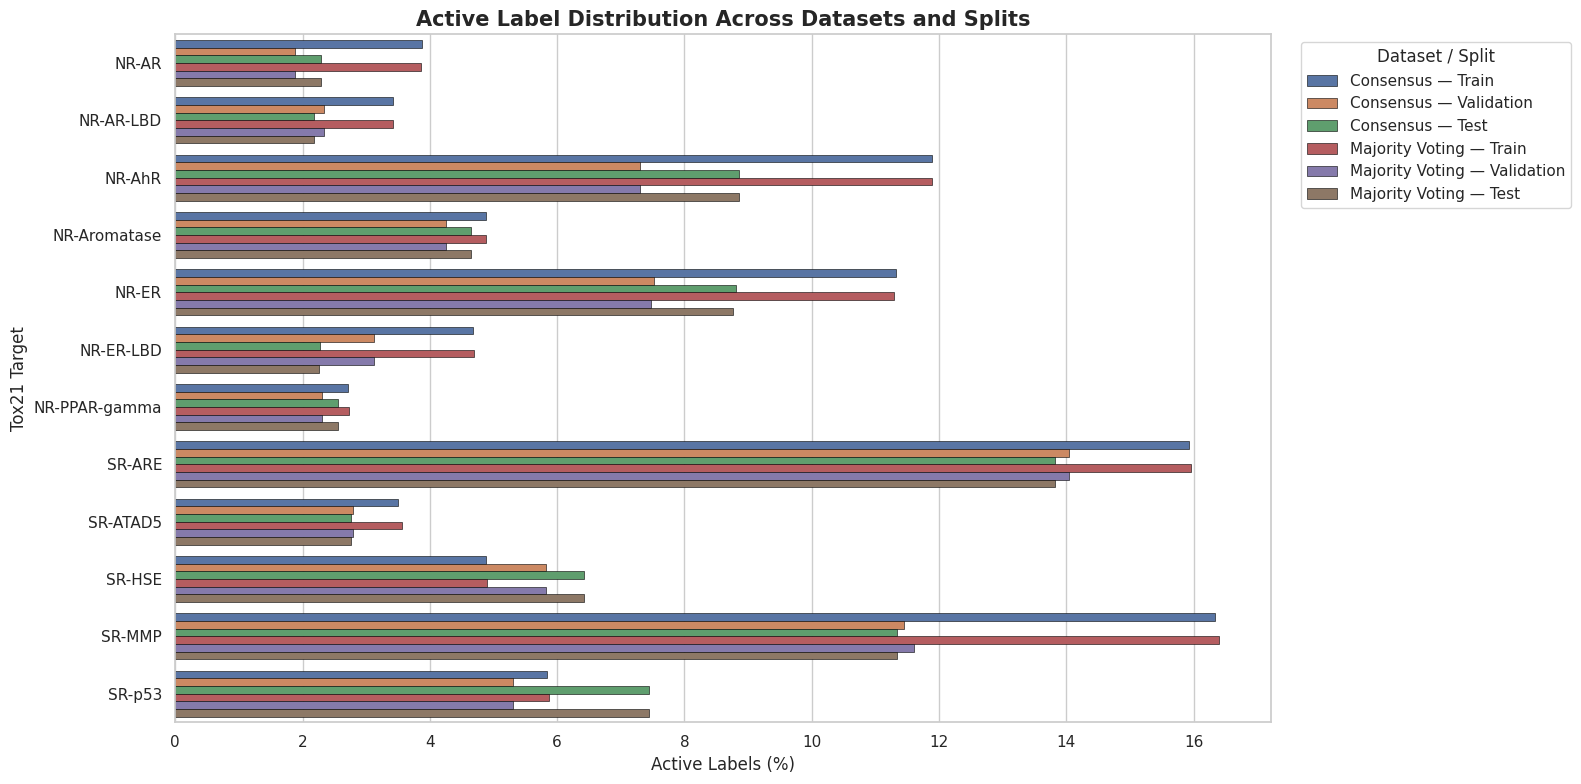

In [26]:

sns.set_theme(style="whitegrid")

datasets_to_plot = {
    "Consensus": {
        "Train": consensus_train,
        "Validation": consensus_val,
        "Test": consensus_test
    },
    "Majority Voting": {
        "Train": majority_train,
        "Validation": majority_val,
        "Test": majority_test
    }
}

results = []

for dataset_name, splits in datasets_to_plot.items():
    for split_name, df_split in splits.items():
        for target in TARGET_NAMES:

            if target not in df_split.columns:
                continue

            labels = pd.to_numeric(
                df_split[target],
                errors="coerce"
            )

            labels = labels[labels.isin([0, 1])]

            if len(labels) == 0:
                continue

            results.append({
                "Dataset": dataset_name,
                "Split": split_name,
                "Target": target,
                "Active (%)": (labels == 1).mean() * 100
            })

plot_df = pd.DataFrame(results)

plot_df["Dataset / Split"] = (
    plot_df["Dataset"] + " — " + plot_df["Split"]
)

plt.figure(figsize=(16, 8))

sns.barplot(
    data=plot_df,
    x="Active (%)",
    y="Target",
    hue="Dataset / Split",
    hue_order=[
        "Consensus — Train",
        "Consensus — Validation",
        "Consensus — Test",
        "Majority Voting — Train",
        "Majority Voting — Validation",
        "Majority Voting — Test"
    ],
    edgecolor="black",
    linewidth=0.4
)

plt.title(
    "Active Label Distribution Across Datasets and Splits",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Active Labels (%)")
plt.ylabel("Tox21 Target")
plt.legend(
    title="Dataset / Split",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [27]:
functional_groups = {
    "Alcohol": "[OX2H][CX4]",
    "Ketone": "[#6][CX3](=O)[#6]",
    "Carboxylic acid": "[CX3](=O)[OX2H1]",
    "Ester": "[CX3](=O)[OX2H0][#6]",
    "Ether": "[OD2]([#6;!$(C=O)])[#6;!$(C=O)]",
    "Primary Amine": "[NX3H2;!$(NC=O)]",
    "Secondary Amine": "[NX3H1;!$(NC=O)]",
    "Tertiary Amine": "[NX3H0;!$(NC=O)]",
    "Amide": "[NX3][CX3](=[OX1])",
    "Nitro": "[N+](=O)[O-]",
    "Sulfide": "[#16X2H0]([#6])[#6]",
    "Nitrile": "[CX2]#[NX1]",
    "Halogen": "[F,Cl,Br,I]",
    "Aromatic ring": "a1aaaaa1",
    "Phenol": "[c][OX2H]",
    "Aniline": "[c][NH2]",
    "Sulfonamide": "[SX4](=O)(=O)[NX3]",
    "Phosphate": "[PX4](=O)([OX2])[OX2]",
    "Alkene": "[CX3]=[CX3]",
}

functional_group_mols = {
    name: Chem.MolFromSmarts(smarts)
    for name, smarts in functional_groups.items()
}


def safe_mol(smiles):
    if not isinstance(smiles, str) or not smiles:
        return None
    try:
        return Chem.MolFromSmiles(smiles, sanitize=True)
    except Exception:
        return None

def count_functional_groups(mol, binary=True):
    if mol is None:
        return {name: 0 for name in functional_groups}

    counts = {}
    for name, fg_mol in functional_group_mols.items():
        if fg_mol is None:
            counts[name] = 0
            continue
        try:
            matches = mol.GetSubstructMatches(fg_mol, uniquify=True)
            counts[name] = int(len(matches) > 0) if binary else len(matches)
        except:
            counts[name] = 0
    return counts


def build_fg_features(df, smiles_col="smiles", binary=True):
    mols = df[smiles_col].apply(safe_mol)
    fg_counts = mols.apply(lambda m: count_functional_groups(m, binary=binary))
    fg_df = pd.DataFrame(fg_counts.tolist())
    df_out = pd.concat([df.reset_index(drop=True), fg_df], axis=1)
    return df_out

consensus_train_fg = build_fg_features(consensus_train, smiles_col="smiles", binary=False)
consensus_val_fg = build_fg_features(consensus_val, smiles_col="smiles", binary=False)
consensus_test_fg = build_fg_features(consensus_test, smiles_col="smiles", binary=False)

majority_train_fg = build_fg_features(majority_train, smiles_col="smiles", binary=False)
majority_val_fg = build_fg_features(majority_val, smiles_col="smiles", binary=False)
majority_test_fg = build_fg_features(majority_test, smiles_col="smiles", binary=False)

print("Functional Group features attached successfully to both Consensus and Majority splits.")
print(f"Consensus Train FG shape: {consensus_train_fg.shape}")
print(f"Consensus Val FG shape:   {consensus_val_fg.shape}")
print(f"Consensus Test FG shape:  {consensus_test_fg.shape}")
print(f"Majority Train FG shape:  {majority_train_fg.shape}")
print(f"Majority Val FG shape:    {majority_val_fg.shape}")
print(f"Majority Test FG shape:   {majority_test_fg.shape}")


[09:54:38] WARNING: not removing hydrogen atom without neighbors
[09:54:40] WARNING: not removing hydrogen atom without neighbors


Functional Group features attached successfully to both Consensus and Majority splits.
Consensus Train FG shape: (6433, 33)
Consensus Val FG shape:   (804, 33)
Consensus Test FG shape:  (804, 33)
Majority Train FG shape:  (6433, 33)
Majority Val FG shape:    (804, 33)
Majority Test FG shape:   (804, 33)



Calculating enrichment for CONSENSUS dataset...
Enrichment profiles calculated and attached to CONSENSUS dataset.

Calculating enrichment for MAJORITY dataset...
Enrichment profiles calculated and attached to MAJORITY dataset.


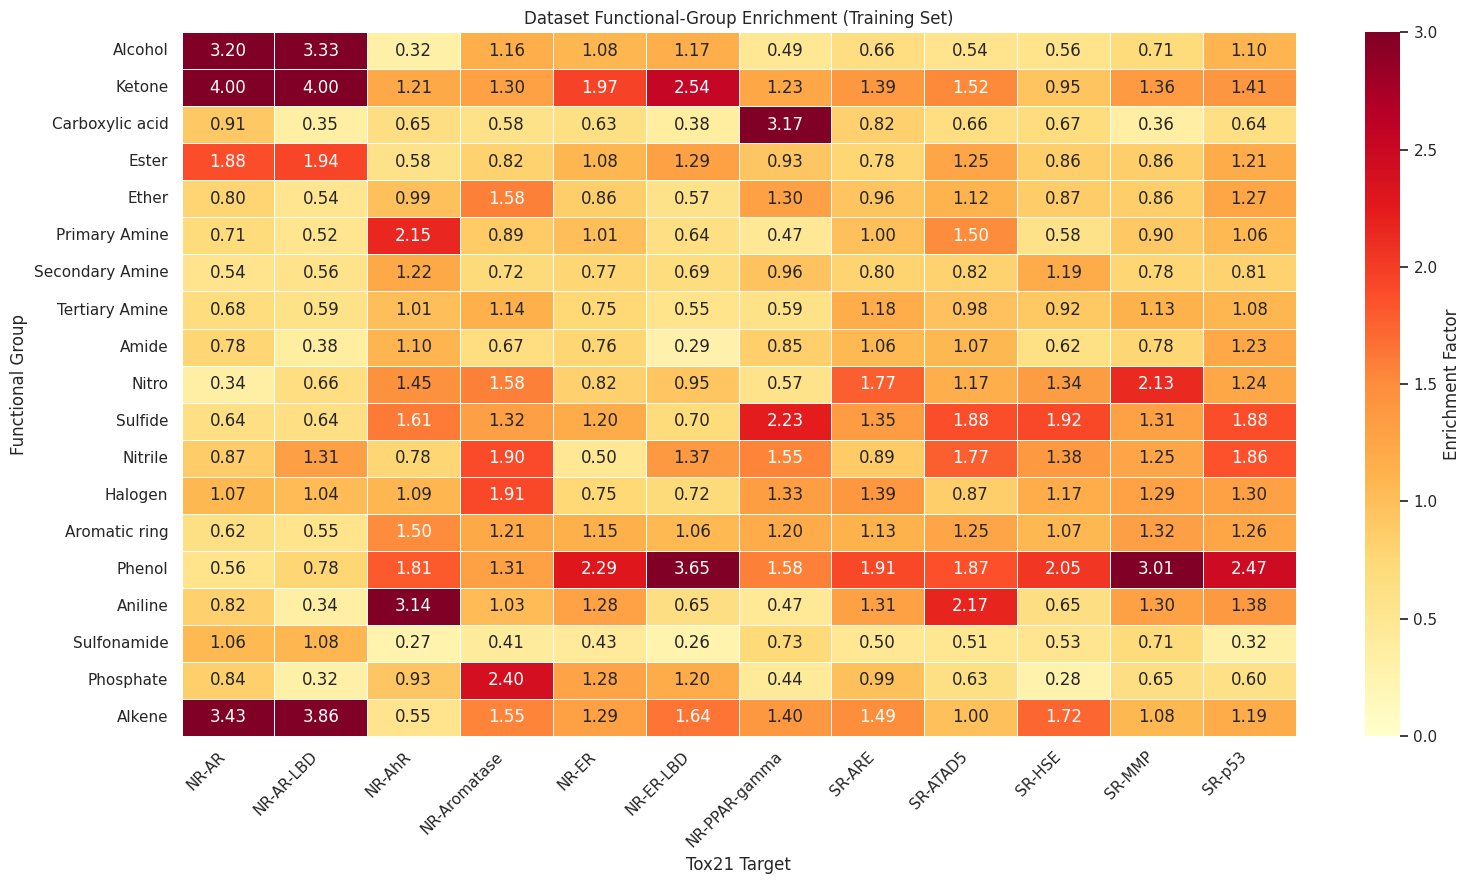

In [28]:

from sklearn.model_selection import GroupKFold

FG_COLS = list(functional_groups.keys())
EF_PROFILE_COLS = [f"EF_PROFILE_{target}" for target in TARGET_NAMES]
OUTPUT_DIR = "output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

def compute_enrichment(frame, target_names=TARGET_NAMES, fg_cols=FG_COLS, alpha=1.0, min_samples=10):
    if alpha <= 0:
        raise ValueError("alpha must be greater than zero.")
    if min_samples < 1:
        raise ValueError("min_samples must be at least 1.")

    required = list(target_names) + list(fg_cols)
    missing = [c for c in required if c not in frame.columns]
    if missing:
        raise ValueError(f"Missing columns: {missing}")

    rows = []
    for target in target_names:
        y_all = pd.to_numeric(frame[target], errors="coerce").to_numpy(dtype=float)
        valid = np.isin(y_all, [0.0, 1.0])
        y = y_all[valid]
        n_total = len(y)

        if n_total == 0:
            for fg in fg_cols:
                rows.append({
                    "Target": target, "Functional_Group": fg,
                    "N_Total": 0, "N_Active_Total": 0,
                    "N_with_FG": 0, "N_Active_with_FG": 0,
                    "Global_Active_Rate": np.nan,
                    "FG_Active_Rate": np.nan,
                    "Enrichment_Factor": np.nan
                })
            continue

        n_active = int((y == 1).sum())
        p_global = (n_active + alpha) / (n_total + 2 * alpha)

        for fg in fg_cols:
            fg_all = pd.to_numeric(frame[fg], errors="coerce").to_numpy(dtype=float)
            fg_labeled = fg_all[valid]
            presence = np.isfinite(fg_labeled) & (fg_labeled > 0)
            y_fg = y[presence]
            n_fg = int(presence.sum())
            n_active_fg = int((y_fg == 1).sum())

            if n_fg >= min_samples:
                p_fg = (n_active_fg + alpha) / (n_fg + 2 * alpha)
                ef = p_fg / p_global
            else:
                p_fg = np.nan
                ef = np.nan

            rows.append({
                "Target": target,
                "Functional_Group": fg,
                "N_Total": n_total,
                "N_Active_Total": n_active,
                "N_with_FG": n_fg,
                "N_Active_with_FG": n_active_fg,
                "Global_Active_Rate": p_global,
                "FG_Active_Rate": p_fg,
                "Enrichment_Factor": ef
            })

    return pd.DataFrame(rows)

def log_enrichment_matrix(frame, alpha=1.0, min_samples=10):
    ef_df = compute_enrichment(frame, target_names=TARGET_NAMES, fg_cols=FG_COLS, alpha=alpha, min_samples=min_samples)
    raw = (
        ef_df.pivot(index="Functional_Group", columns="Target", values="Enrichment_Factor")
        .reindex(index=FG_COLS, columns=TARGET_NAMES)
        .fillna(1.0)
        .clip(lower=0.25, upper=4.0)
    )
    return np.log2(raw).to_numpy(dtype=np.float32), ef_df, raw

def profiles_from_matrix(frame, log_ef_matrix):
    presence = (frame[FG_COLS].to_numpy(dtype=np.float32) > 0).astype(np.float32)
    profile_sum = presence @ np.asarray(log_ef_matrix, dtype=np.float32)
    denominator = presence.sum(axis=1, keepdims=True)
    profiles = np.divide(
        profile_sum, denominator,
        out=np.zeros_like(profile_sum),
        where=denominator > 0
    )
    return profiles.astype(np.float32)

def process_enrichment_for_dataset(train_df, val_df, test_df, dataset_prefix):
    print(f"\nCalculating enrichment for {dataset_prefix.upper()} dataset...")
    full_log_ef, enrichment_df, enrichment_matrix = log_enrichment_matrix(train_df, alpha=1.0, min_samples=10)
    enrichment_df.to_csv(os.path.join(OUTPUT_DIR, f"fg_enrichment_{dataset_prefix}_training.csv"), index=False)

    n_scaffolds = train_df["scaffold"].nunique()
    n_splits = min(5, n_scaffolds)
    if n_splits < 2:
        raise ValueError("At least two training scaffold groups are required for EF cross-fitting.")

    train_profiles = np.zeros((len(train_df), len(TARGET_NAMES)), dtype=np.float32)
    groups = train_df["scaffold"].to_numpy()
    gkf = GroupKFold(n_splits=n_splits)

    for fold, (fit_idx, held_idx) in enumerate(gkf.split(train_df, groups=groups), start=1):
        fold_fit = train_df.iloc[fit_idx]
        fold_held = train_df.iloc[held_idx]
        fold_log_ef, _, _ = log_enrichment_matrix(fold_fit, alpha=1.0, min_samples=10)
        train_profiles[held_idx] = profiles_from_matrix(fold_held, fold_log_ef)

    val_profiles = profiles_from_matrix(val_df, full_log_ef)
    test_profiles = profiles_from_matrix(test_df, full_log_ef)

    for frame, profiles in [(train_df, train_profiles), (val_df, val_profiles), (test_df, test_profiles)]:
        for j, col in enumerate(EF_PROFILE_COLS):
            frame[col] = profiles[:, j]

    print(f"Enrichment profiles calculated and attached to {dataset_prefix.upper()} dataset.")
    return full_log_ef, enrichment_matrix

# Calculate and attach profiles for Consensus
consensus_full_log_ef, consensus_enrichment_matrix = process_enrichment_for_dataset(
    consensus_train_fg, consensus_val_fg, consensus_test_fg, "consensus"
)

# Calculate and attach profiles for Majority Voting
majority_full_log_ef, majority_enrichment_matrix = process_enrichment_for_dataset(
    majority_train_fg, majority_val_fg, majority_test_fg, "majority"
)

# Plotting training-only enrichment heatmap (Consensus as reference)
plt.figure(figsize=(16, 9))
sns.heatmap(
    consensus_enrichment_matrix, annot=True, fmt=".2f", cmap="YlOrRd",
    vmin=0, vmax=3, linewidths=0.4,
    cbar_kws={"label": "Enrichment Factor"}
)
plt.title("Dataset Functional-Group Enrichment (Training Set)")
plt.xlabel("Tox21 Target")
plt.ylabel("Functional Group")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "fg_enrichment_heatmap.png"), dpi=300, bbox_inches="tight")
plt.show()


In [30]:

def compute_descriptor(mol):
    return torch.tensor([
        np.log1p(Descriptors.MolWt(mol)),
        Descriptors.MolLogP(mol),
        Descriptors.NumHDonors(mol),
        Descriptors.NumHAcceptors(mol),
        np.log1p(Descriptors.TPSA(mol)),
    ], dtype=torch.float32)

def compute_desc_stats(df):
    all_desc = []
    for smi in df["smiles"]:
        mol = Chem.MolFromSmiles(smi)
        if mol is None:
            continue
        desc = compute_descriptor(mol)
        if torch.isfinite(desc).all():
            all_desc.append(desc)
    if not all_desc:
        raise ValueError("No valid molecular descriptors found in the training split.")
    all_desc = torch.stack(all_desc)
    mean = all_desc.mean(dim=0)
    std = all_desc.std(dim=0, unbiased=False)
    std[std == 0] = 1.0
    return mean, std

print("Calculating descriptor statistics for CONSENSUS train split...")
consensus_desc_train_mean, consensus_desc_train_std = compute_desc_stats(consensus_train_fg)

print("Calculating descriptor statistics for MAJORITY train split...")
majority_desc_train_mean, majority_desc_train_std = compute_desc_stats(majority_train_fg)


Calculating descriptor statistics for CONSENSUS train split...


[09:55:45] WARNING: not removing hydrogen atom without neighbors


Calculating descriptor statistics for MAJORITY train split...


[09:55:50] WARNING: not removing hydrogen atom without neighbors


In [31]:


class ToxicityDataset(Dataset):
    def __init__(self, df, desc_mean, desc_std):
        super().__init__()
        self.df = df.reset_index(drop=True).copy()
        self.processed_data_list = []
        self.func_cols = FG_COLS
        self.target_cols = TARGET_NAMES
        self.ef_cols = EF_PROFILE_COLS

        self.desc_mean = desc_mean.detach().cpu().float() if desc_mean is not None else None
        self.desc_std = desc_std.detach().cpu().float() if desc_std is not None else None
        self._process()

    def _process(self):
        for _, row in self.df.iterrows():
            mol = Chem.MolFromSmiles(row["smiles"], sanitize=True)
            if mol is None:
                continue

            # Atom features
            node_feats = []
            for atom in mol.GetAtoms():
                node_feats.append([
                    atom.GetAtomicNum() / 20.0,
                    atom.GetDegree() / 4.0,
                    float(atom.GetIsAromatic()),
                    atom.GetFormalCharge() / 3.0,
                    atom.GetTotalNumHs() / 4.0
                ])
            x = torch.tensor(node_feats, dtype=torch.float32)

            # Bond features
            edges = []
            edge_features = []
            for bond in mol.GetBonds():
                i = bond.GetBeginAtomIdx()
                j = bond.GetEndAtomIdx()
                bond_type = bond.GetBondType()
                bf = [
                    float(bond_type == Chem.rdchem.BondType.SINGLE),
                    float(bond_type == Chem.rdchem.BondType.DOUBLE),
                    float(bond_type == Chem.rdchem.BondType.TRIPLE),
                    float(bond_type == Chem.rdchem.BondType.AROMATIC),
                    float(bond.GetIsConjugated()),
                    float(bond.IsInRing())
                ]
                edges.extend([[i, j], [j, i]])
                edge_features.extend([bf, bf])

            if edges:
                edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
                edge_attr = torch.tensor(edge_features, dtype=torch.float32)
            else:
                edge_index = torch.empty((2, 0), dtype=torch.long)
                edge_attr = torch.empty((0, 6), dtype=torch.float32)

            # Functional group features
            fg_values = pd.to_numeric(row[self.func_cols], errors="coerce").to_numpy(dtype=np.float32)
            fg_values = np.log1p(np.clip(fg_values, a_min=0.0, a_max=None))
            if not np.isfinite(fg_values).all():
                raise ValueError(f"Invalid FG features for {row['smiles']}")
            fg = torch.tensor(fg_values, dtype=torch.float32)

            # Molecular descriptors
            desc = compute_descriptor(mol).float()
            if not torch.isfinite(desc).all():
                raise ValueError(f"Invalid descriptors for {row['smiles']}")
            if self.desc_mean is not None:
                desc = (desc - self.desc_mean) / self.desc_std.clamp(min=1e-6)
                desc = torch.clamp(desc, -5, 5)

            # EF Profile
            ef_profile_np = pd.to_numeric(row[self.ef_cols], errors="coerce").to_numpy(dtype=np.float32)
            if not np.isfinite(ef_profile_np).all():
                raise ValueError(f"Invalid EF profile for {row['smiles']}")
            ef_profile = torch.tensor(ef_profile_np, dtype=torch.float32).view(1, -1)

            # Labels & Masks
            y_raw = pd.to_numeric(row[self.target_cols], errors="coerce").to_numpy(dtype=np.float32)
            mask_np = np.isfinite(y_raw)
            valid_labels = np.isin(y_raw[mask_np], [0.0, 1.0])
            if not valid_labels.all():
                raise ValueError(f"Non-binary target for {row['smiles']}")

            y_clean = np.where(mask_np, y_raw, 0.0)
            y = torch.tensor(y_clean, dtype=torch.float32).view(1, -1)
            mask = torch.tensor(mask_np.astype(np.float32)).view(1, -1)

            self.processed_data_list.append(
                Data(
                    x=x, edge_index=edge_index, edge_attr=edge_attr,
                    y=y, mask=mask, fg=fg.view(1, -1),
                    descriptors=desc.view(1, -1), ef_profile=ef_profile
                )
            )

    def __len__(self):
        return len(self.processed_data_list)

    def __getitem__(self, idx):
        return self.processed_data_list[idx]

# --- 1. Construct Consensus Datasets and Loaders ---
print("Processing Consensus Datasets...")
consensus_dataset_train = ToxicityDataset(consensus_train_fg, consensus_desc_train_mean, consensus_desc_train_std)
consensus_dataset_val = ToxicityDataset(consensus_val_fg, consensus_desc_train_mean, consensus_desc_train_std)
consensus_dataset_test = ToxicityDataset(consensus_test_fg, consensus_desc_train_mean, consensus_desc_train_std)

consensus_train_loader = DataLoader(consensus_dataset_train, batch_size=16, shuffle=True)
consensus_val_loader = DataLoader(consensus_dataset_val, batch_size=16, shuffle=False)
consensus_test_loader = DataLoader(consensus_dataset_test, batch_size=16, shuffle=False)

# --- 2. Construct Majority Voting Datasets and Loaders ---
print("Processing Majority Voting Datasets...")
majority_dataset_train = ToxicityDataset(majority_train_fg, majority_desc_train_mean, majority_desc_train_std)
majority_dataset_val = ToxicityDataset(majority_val_fg, majority_desc_train_mean, majority_desc_train_std)
majority_dataset_test = ToxicityDataset(majority_test_fg, majority_desc_train_mean, majority_desc_train_std)

majority_train_loader = DataLoader(majority_dataset_train, batch_size=16, shuffle=True)
majority_val_loader = DataLoader(majority_dataset_val, batch_size=16, shuffle=False)
majority_test_loader = DataLoader(majority_dataset_test, batch_size=16, shuffle=False)

# Retain standard variables for downstream legacy code cells referencing data_train/val/test
data_train = consensus_dataset_train
data_val = consensus_dataset_val
data_test = consensus_dataset_test
train_loader = consensus_train_loader
val_loader = consensus_val_loader
test_loader = consensus_test_loader

print(f"\nConsensus - Train: {len(consensus_dataset_train)} | Val: {len(consensus_dataset_val)} | Test: {len(consensus_dataset_test)}")
print(f"Majority  - Train: {len(majority_dataset_train)} | Val: {len(majority_dataset_val)} | Test: {len(majority_dataset_test)}")

Processing Consensus Datasets...


[09:56:06] WARNING: not removing hydrogen atom without neighbors


Processing Majority Voting Datasets...


[09:56:31] WARNING: not removing hydrogen atom without neighbors



Consensus - Train: 6433 | Val: 804 | Test: 804
Majority  - Train: 6433 | Val: 804 | Test: 804


In [32]:
all_graphs = list(majority_dataset_train) + list(majority_dataset_test) + list(majority_dataset_val)

no_bond_graphs = [
    i for i, g in enumerate(all_graphs)
    if g.edge_index.shape[1] == 0
]

invalid_graphs = [
    i for i, g in enumerate(all_graphs)
    if (
        not torch.isfinite(g.x).all()
        or not torch.isfinite(g.edge_attr).all()
        or not torch.isfinite(g.fg).all()
        or not torch.isfinite(g.descriptors).all()
    )
]

print("Graphs without bonds:", len(no_bond_graphs))
print("Graphs with non-finite features:", len(invalid_graphs))

no_bond_graphs = [
    (i, all_graphs[i]) for i in no_bond_graphs
]
invalid_graphs = [
    (i, all_graphs[i]) for i in invalid_graphs
]

all_dfs = pd.concat([majority_train_fg, majority_val_fg, majority_test_fg], ignore_index=True)

print("=== SMILES of Graphs without Bonds ===")
for idx, graph in no_bond_graphs:
    smiles = all_dfs.iloc[idx]['smiles']
    print(f"Graph Index: {idx:4d} | Atoms: {graph.x.shape[0]} | SMILES: {smiles}")

Graphs without bonds: 11
Graphs with non-finite features: 0
=== SMILES of Graphs without Bonds ===
Graph Index: 2286 | Atoms: 3 | SMILES: [Cl-].[Cl-].[Cu+2]
Graph Index: 4082 | Atoms: 3 | SMILES: [Cl-].[Cl-].[Fe+2]
Graph Index: 5580 | Atoms: 2 | SMILES: [Br-].[Na+]
Graph Index: 5634 | Atoms: 3 | SMILES: [Cl-].[Cl-].[SnH2+2]
Graph Index: 6639 | Atoms: 3 | SMILES: CS(=O)(=O)OCCCCOS(C)(=O)=O
Graph Index: 6641 | Atoms: 3 | SMILES: OC(CCN1CCCCC1)(c1ccccc1)c1ccccc1
Graph Index: 7097 | Atoms: 5 | SMILES: FC(F)(F)C(F)(F)C(F)(F)C(F)(F)C(F)(F)C(F)(F)C(F)(F)C(F)(F)C(F)(F)C(F)(F)F
Graph Index: 7496 | Atoms: 3 | SMILES: CCCCN1C(=O)[C@@H]([C@H](O)C2CCCCC2)NC(=O)C12CCN(Cc1ccc(Oc3ccc(C(=O)O)cc3)cc1)CC2.Cl
Graph Index: 7758 | Atoms: 4 | SMILES: NC(=S)C(N)=S
Graph Index: 7913 | Atoms: 3 | SMILES: C[N+](C)(C)CCO.[OH-]
Graph Index: 7915 | Atoms: 2 | SMILES: CC(C)Br


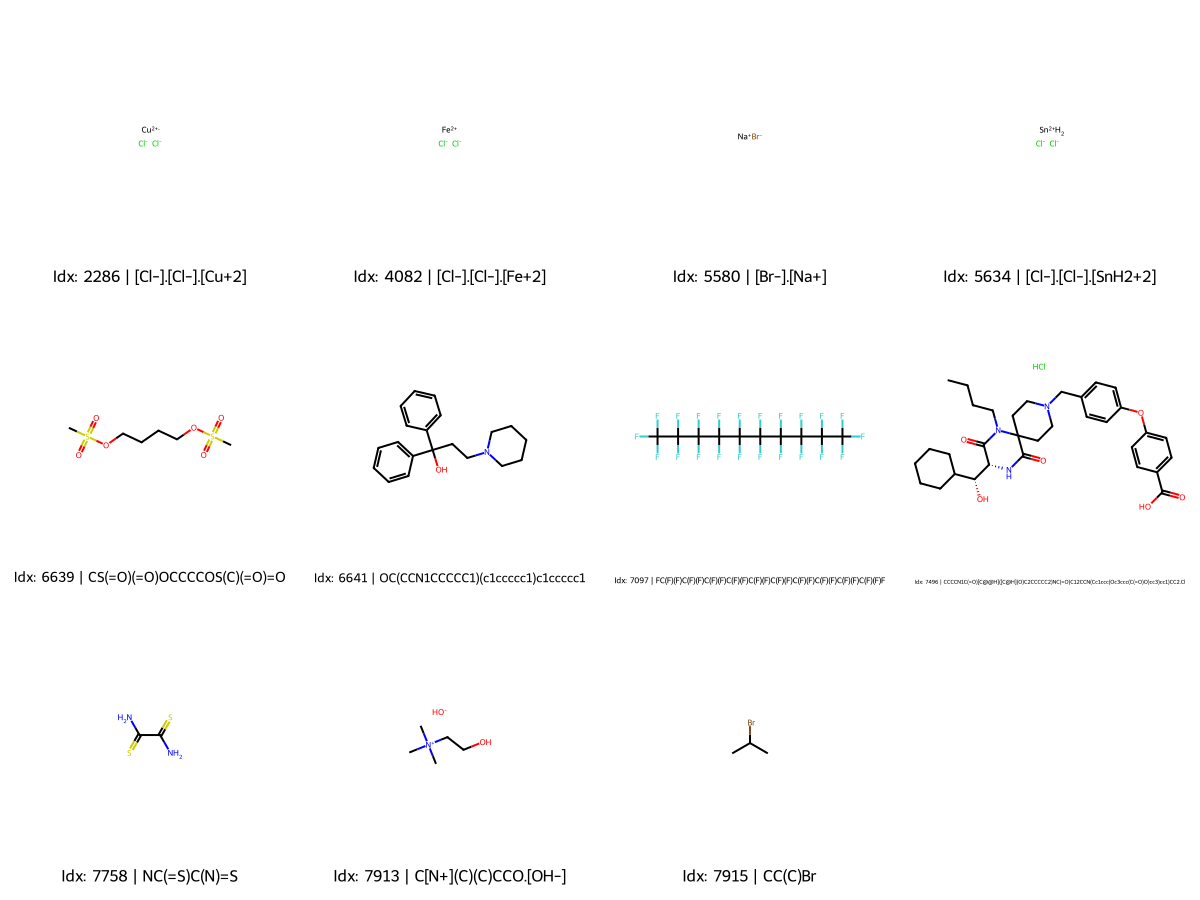

In [34]:
from rdkit.Chem import Draw

mols_to_draw = []
legends = []

for idx, graph in no_bond_graphs:
    smiles = all_dfs.iloc[idx]['smiles']
    mol = Chem.MolFromSmiles(smiles)
    if mol is not None:
        mols_to_draw.append(mol)
        legends.append(f"Idx: {idx} | {smiles}")

img = Draw.MolsToGridImage(
    mols_to_draw,
    molsPerRow=4,
    subImgSize=(300, 300),
    legends=legends
)

display(img)

In [35]:


num_atoms = []
num_bonds = []
dataset = majority_dataset_train + majority_dataset_test + majority_dataset_val
for data in dataset:
    num_atoms.append(data.x.shape[0])
    num_bonds.append(data.edge_index.shape[1] // 2)

print("Molecules:", len(dataset))

print("\nAtoms:")
print("Mean:", np.mean(num_atoms))
print("Min:", np.min(num_atoms))
print("Max:", np.max(num_atoms))

print("\nBonds:")
print("Mean:", np.mean(num_bonds))
print("Min:", np.min(num_bonds))
print("Max:", np.max(num_bonds))

print("\nNode feature dimension:", dataset[0].x.shape[1])
print("Edge feature dimension:", dataset[0].edge_attr.shape[1])
print("Functional groups:", dataset[0].fg.shape[1])
print("Descriptors:", dataset[0].descriptors.shape[1])
print("Targets:", dataset[0].y.shape[1])

Molecules: 8041

Atoms:
Mean: 18.896654644944658
Min: 2
Max: 132

Bonds:
Mean: 19.390374331550802
Min: 0
Max: 145

Node feature dimension: 5
Edge feature dimension: 6
Functional groups: 19
Descriptors: 5
Targets: 12


In [36]:


class EnrichmentConditionedGPSLayer(nn.Module):
    """
    Local GINE message passing + global multi-head self-attention.
    The molecule-level EF context conditions the local/global fusion gate.
    """
    def __init__(self, hidden_dim, edge_dim, heads=4, dropout=0.1):
        super().__init__()
        if hidden_dim % heads != 0:
            raise ValueError("hidden_dim must be divisible by heads.")

        self.hidden_dim = hidden_dim
        self.heads = heads
        self.head_dim = hidden_dim // heads

        local_mlp = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, hidden_dim)
        )
        self.local_conv = GINEConv(local_mlp, edge_dim=edge_dim)

        self.q_proj = nn.Linear(hidden_dim, hidden_dim)
        self.k_proj = nn.Linear(hidden_dim, hidden_dim)
        self.v_proj = nn.Linear(hidden_dim, hidden_dim)
        self.out_proj = nn.Linear(hidden_dim, hidden_dim)

        # EF context now conditions the fusion gate (3 * hidden_dim).
        self.gate = nn.Sequential(
            nn.Linear(hidden_dim * 3, hidden_dim),
            nn.Sigmoid()
        )
        self.norm = nn.LayerNorm(hidden_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, edge_index, edge_attr, batch, ef_context):
        h_local = self.local_conv(x, edge_index, edge_attr)

        x_dense, mask = to_dense_batch(x, batch)
        B, N, D = x_dense.shape

        q = self.q_proj(x_dense).view(
            B, N, self.heads, self.head_dim
        ).transpose(1, 2)
        k = self.k_proj(x_dense).view(
            B, N, self.heads, self.head_dim
        ).transpose(1, 2)
        v = self.v_proj(x_dense).view(
            B, N, self.heads, self.head_dim
        ).transpose(1, 2)

        scores = torch.matmul(q, k.transpose(-2, -1)) / (self.head_dim ** 0.5)
        key_mask = ~mask[:, None, None, :]
        scores = scores.masked_fill(
            key_mask, torch.finfo(scores.dtype).min
        )

        attn_weights = F.softmax(scores, dim=-1)
        attn_weights = self.dropout(attn_weights)
        h_global_dense = torch.matmul(attn_weights, v)
        h_global_dense = h_global_dense.transpose(1, 2).contiguous().view(B, N, D)
        h_global = self.out_proj(h_global_dense)[mask]

        # Broadcast the graph-level enrichment context to each atom.
        ef_nodes = ef_context[batch]
        gate_input = torch.cat([h_local, h_global, ef_nodes], dim=-1)
        gate = self.gate(gate_input)

        h = gate * h_local + (1.0 - gate) * h_global
        return self.norm(x + self.dropout(h))


class Tox21EnrichmentAttModel(nn.Module):
    """
    Multitask Tox21 model. Enrichment profiles are computed outside the
    model from training labels only, with scaffold-grouped cross-fitting
    for training examples, and passed as data.ef_profile.
    """
    def __init__(
        self, in_channels, edge_dim, desc_dim, fg_dim,
        hidden=128, heads=4, num_layers=3, dropout=0.1
    ):
        super().__init__()

        self.atom_encoder = nn.Linear(in_channels, hidden)

        self.desc_proj = nn.Sequential(
            nn.Linear(desc_dim, hidden),
            nn.GELU(),
            nn.Linear(hidden, hidden)
        )
        self.fg_proj = nn.Sequential(
            nn.Linear(fg_dim, hidden),
            nn.GELU(),
            nn.Linear(hidden, hidden)
        )
        self.ef_context_proj = nn.Sequential(
            nn.Linear(len(TARGET_NAMES), hidden),
            nn.GELU(),
            nn.Linear(hidden, hidden)
        )

        self.input_fusion = nn.Sequential(
            nn.Linear(hidden * 3, hidden),
            nn.GELU(),
            nn.LayerNorm(hidden)
        )

        self.gps_layers = nn.ModuleList([
            EnrichmentConditionedGPSLayer(
                hidden, edge_dim, heads=heads, dropout=dropout
            )
            for _ in range(num_layers)
        ])

        self.readout = nn.Sequential(
            nn.Linear(hidden * 2, 256),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(256, 128),
            nn.GELU()
        )
        self.output_heads = nn.ModuleList([
            nn.Linear(128, 1) for _ in TARGET_NAMES
        ])

    def forward(self, data):
        x = data.x.float()
        edge_index = data.edge_index
        edge_attr = data.edge_attr.float()
        batch = data.batch

        desc = torch.nan_to_num(data.descriptors.float())
        fg = torch.nan_to_num(data.fg.float()).clamp(min=0)
        ef_profile = torch.nan_to_num(data.ef_profile.float())

        ef_context = self.ef_context_proj(ef_profile)

        x_atom = self.atom_encoder(x)
        desc_embed = self.desc_proj(desc)[batch]
        fg_embed = self.fg_proj(fg)[batch]

        x_fused = self.input_fusion(
            torch.cat([x_atom, desc_embed, fg_embed], dim=-1)
        )

        for layer in self.gps_layers:
            x_fused = layer(
                x_fused, edge_index, edge_attr, batch, ef_context
            )

        x_mean = global_mean_pool(x_fused, batch)
        x_max = global_max_pool(x_fused, batch)
        x_pool = torch.cat([x_mean, x_max], dim=-1)
        x_out = self.readout(x_pool)

        # Raw logits [batch_size, 12], suitable for BCEWithLogitsLoss.
        return torch.cat([head(x_out) for head in self.output_heads], dim=1)


In [37]:

model_consensus = Tox21EnrichmentAttModel(
    in_channels=consensus_dataset_train[0].x.shape[1],
    edge_dim=consensus_dataset_train[0].edge_attr.shape[1],
    desc_dim=consensus_dataset_train[0].descriptors.shape[1],
    fg_dim=consensus_dataset_train[0].fg.shape[1],
    hidden=128,
    heads=4,
    num_layers=3,
    dropout=0.1
).to(device)

# 2. Initialize Majority Voting Model
model_majority = Tox21EnrichmentAttModel(
    in_channels=majority_dataset_train[0].x.shape[1],
    edge_dim=majority_dataset_train[0].edge_attr.shape[1],
    desc_dim=majority_dataset_train[0].descriptors.shape[1],
    fg_dim=majority_dataset_train[0].fg.shape[1],
    hidden=128,
    heads=4,
    num_layers=3,
    dropout=0.1
).to(device)

In [38]:

def compute_pos_weight(loader, device, max_weight=20.0):
    total_pos = None
    total_count = None

    for data in loader:
        y = data.y
        mask = data.mask

        if y.dim() == 3:
            y = y.squeeze(1)
        if mask.dim() == 3:
            mask = mask.squeeze(1)

        y = y.to(device).float()
        mask = mask.to(device).float()

        pos = (y * mask).sum(dim=0)
        count = mask.sum(dim=0)

        if total_pos is None:
            total_pos = pos.clone()
            total_count = count.clone()
        else:
            total_pos += pos
            total_count += count
    total_neg = total_count - total_pos


    pos_weight = torch.sqrt(
        total_neg / total_pos.clamp(min=1.0)
    )

    pos_weight = torch.clamp(
        pos_weight,
        min=1.0,
        max=max_weight
    )

    return pos_weight.float()

def train_epoch(model, loader, optimizer, criterion, device, scaler):
    model.train()

    total_loss = 0.0
    total_observed = 0

    use_amp = (
        CONFIG["use_amp"]
        and torch.device(device).type == "cuda"
    )

    for data in loader:
        data = data.to(device)
        optimizer.zero_grad(set_to_none=True)

        y_targets = data.y
        mask = data.mask

        if y_targets.dim() == 3:
            y_targets = y_targets.squeeze(1)

        if mask.dim() == 3:
            mask = mask.squeeze(1)

        y_targets = y_targets.float()
        mask = mask.float()

        with torch.amp.autocast(
            device_type=torch.device(device).type,
            enabled=use_amp
        ):
            logits = model(data)

            if logits.shape != y_targets.shape:
                raise ValueError(
                    f"Shape mismatch: logits={logits.shape}, "
                    f"targets={y_targets.shape}"
                )

            unreduced_loss = criterion(logits, y_targets)

            masked_loss = unreduced_loss * mask

            loss = masked_loss.sum() / mask.sum().clamp(min=1.0)

        if use_amp:
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=5.0
            )

            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=5.0
            )

            optimizer.step()

        observed = int(mask.sum().item())
        total_loss += loss.item() * observed
        total_observed += observed

    if total_observed == 0:
        raise ValueError("No observed labels found in training loader.")

    return total_loss / total_observed

In [39]:
# Compute positive-class weights separately for both datasets to match their distribution accurately.
pos_weight_consensus = compute_pos_weight(consensus_train_loader, device, max_weight=20.0)
pos_weight_majority = compute_pos_weight(majority_train_loader, device, max_weight=20.0)

# Configure distinct optimizers for both models
optimizer_consensus = torch.optim.AdamW(model_consensus.parameters(), lr=1e-4, weight_decay=1e-4)
optimizer_majority = torch.optim.AdamW(model_majority.parameters(), lr=1e-4, weight_decay=1e-4)

# Configure separate validation schedulers monitoring validation ROC-AUC in maximize mode
scheduler_consensus = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_consensus, mode="max", factor=0.5, patience=5, min_lr=1e-6
)
scheduler_majority = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_majority, mode="max", factor=0.5, patience=5, min_lr=1e-6
)

print("Consensus Positive-class weights:", pos_weight_consensus.detach().cpu().numpy().round(3))
print("Majority Positive-class weights: ", pos_weight_majority.detach().cpu().numpy().round(3))
print("Schedulers and optimizers configured for both Consensus and Majority models.")

Consensus Positive-class weights: [4.98  5.319 2.723 4.412 2.799 4.517 5.993 2.297 5.247 4.414 2.263 4.015]
Majority Positive-class weights:  [4.985 5.308 2.722 4.414 2.802 4.506 5.972 2.295 5.209 4.408 2.258 4.003]
Schedulers and optimizers configured for both Consensus and Majority models.


In [40]:
class EarlyStopping:
    def __init__(self, patience=15, min_delta=1e-4, mode="min"):
        self.patience = patience
        self.min_delta = min_delta
        self.mode = mode

        if mode not in ("min", "max"):
            raise ValueError("mode must be 'min' or 'max'")

        self.best_score = (
            float("inf") if mode == "min" else -float("inf")
        )

        self.counter = 0
        self.early_stop = False
        self.best_state = None

    def step(self, score, model):
        if score is None:
            return

        if not torch.isfinite(torch.tensor(float(score))):
            self.counter += 1
        else:
            if self.mode == "min":
                improved = score < self.best_score - self.min_delta
            else:
                improved = score > self.best_score + self.min_delta

            if improved:
                self.best_score = float(score)
                self.counter = 0
                self.best_state = copy.deepcopy(model.state_dict())
            else:
                self.counter += 1

        if self.counter >= self.patience:
            self.early_stop = True


In [41]:
def evaluate_arrays_per_task(preds, targets, masks, task_names, thresholds=None):
    """Evaluate already-collected predictions while ignoring missing labels."""
    preds = np.asarray(preds)
    targets = np.asarray(targets)
    masks = np.asarray(masks)

    if not (preds.shape == targets.shape == masks.shape) or preds.ndim != 2:
        raise ValueError("preds, targets, masks must have identical [N, tasks] shapes.")

    if thresholds is None:
        thresholds = np.full(len(task_names), 0.5, dtype=float)

    results = {}
    for i, name in enumerate(task_names):
        valid = (
            (masks[:, i] == 1)
            & np.isfinite(targets[:, i])
            & np.isfinite(preds[:, i])
        )
        y_true = targets[valid, i].astype(int)
        y_prob = preds[valid, i]
        thr = float(thresholds[i]) if np.isfinite(thresholds[i]) else 0.5
        y_pred = (y_prob >= thr).astype(int)

        if len(y_true) == 0:
            results[name] = {k: np.nan for k in [
                "N", "Positives", "Negatives", "Threshold", "Accuracy",
                "BAC", "F1", "Precision", "Recall", "ROC_AUC", "PR_AUC"
            ]}
            continue

        both_classes = len(np.unique(y_true)) == 2
        results[name] = {
            "N": int(len(y_true)),
            "Positives": int(y_true.sum()),
            "Negatives": int(len(y_true) - y_true.sum()),
            "Threshold": thr,
            "Accuracy": accuracy_score(y_true, y_pred),
            "BAC": balanced_accuracy_score(y_true, y_pred) if both_classes else np.nan,
            "F1": f1_score(y_true, y_pred, zero_division=0),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred, zero_division=0),
            "ROC_AUC": roc_auc_score(y_true, y_prob) if both_classes else np.nan,
            "PR_AUC": average_precision_score(y_true, y_prob) if both_classes else np.nan
        }
    return results

def evaluate_per_class(model, loader, device, task_names, thresholds=None):
    preds, targets, masks = collect_outputs(model, loader, device)
    return evaluate_arrays_per_task(
        preds, targets, masks, task_names, thresholds)


In [42]:
def get_best_roc_thresholds(preds, targets, masks):
    """Finds the optimal threshold for each task using validation set Youden Index."""
    preds = np.asarray(preds)
    targets = np.asarray(targets)
    masks = np.asarray(masks)

    num_tasks = preds.shape[1]
    best_thresholds = np.zeros(num_tasks, dtype=float)

    for i in range(num_tasks):
        valid = (masks[:, i] == 1) & np.isfinite(targets[:, i]) & np.isfinite(preds[:, i])
        y_true = targets[valid, i].astype(int)
        y_prob = preds[valid, i]

        if len(np.unique(y_true)) == 2:
            fpr, tpr, thresholds = roc_curve(y_true, y_prob)
            youden_index = tpr - fpr
            best_idx = np.argmax(youden_index)
            best_thresholds[i] = float(thresholds[best_idx])
        else:
            best_thresholds[i] = 0.5

    return best_thresholds

CONFIG = {
    "epochs": 60,
    "save_path_consensus": "GNNFG21_consensus_best.pt",
    "save_path_majority": "GNNFG21_majority_best.pt",
    "use_amp": True,
    "verbose": True,
    "random_seed": 42
}

logging.basicConfig(level=logging.INFO, format="%(message)s")
logger = logging.getLogger("tox21_training")

def compute_pos_weight(loader, device, max_weight=20.0):
    total_pos = None
    total_count = None
    for data in loader:
        y = data.y
        mask = data.mask
        if y.dim() == 3:
            y = y.squeeze(1)
        if mask.dim() == 3:
            mask = mask.squeeze(1)
        y = y.to(device).float()
        mask = mask.to(device).float()
        pos = (y * mask).sum(dim=0)
        count = mask.sum(dim=0)
        if total_pos is None:
            total_pos = pos.clone()
            total_count = count.clone()
        else:
            total_pos += pos
            total_count += count
    if total_pos is None:
        raise ValueError("The DataLoader is empty.")
    total_neg = total_count - total_pos
    if torch.any(total_pos == 0):
        raise ValueError("At least one task has no positive training examples.")
    pos_weight = torch.sqrt(total_neg / total_pos.clamp(min=1.0))
    return torch.clamp(pos_weight, min=1.0, max=max_weight).float()

def aggregate_metrics(task_results):
    """Macro-average finite per-task metrics."""
    metric_names = ["Accuracy", "BAC", "F1", "Precision", "Recall", "ROC_AUC", "PR_AUC"]
    summary = {}
    for metric in metric_names:
        values = [
            float(v[metric]) for v in task_results.values()
            if metric in v and v[metric] is not None and np.isfinite(v[metric])
        ]
        summary[metric] = float(np.mean(values)) if values else np.nan
    return summary

def train_model_v2(model, loaders, optimizer, scheduler, device, save_path, pos_weight=None, early_stopper=None):
    """Generalized model trainer for a given target model and its respective dataloaders."""
    train_loader = loaders["train"]
    val_loader = loaders["val"]
    test_loader = loaders["test"]
    device = torch.device(device)
    model = model.to(device)
    use_amp = bool(CONFIG["use_amp"] and device.type == "cuda")
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    criterion = nn.BCEWithLogitsLoss(
        pos_weight=pos_weight.to(device) if pos_weight is not None else None,
        reduction="none"
    )

    best_val_auc = -float("inf")
    best_state = None
    history = []

    for epoch in range(1, CONFIG["epochs"] + 1):
        train_loss = train_epoch(model, train_loader, optimizer, criterion, device, scaler)
        val_preds, val_targets, val_masks = collect_outputs(model, val_loader, device)
        val_results = evaluate_arrays_per_task(
            val_preds, val_targets, val_masks, TARGET_NAMES, thresholds=np.full(len(TARGET_NAMES), 0.5)
        )
        val_metrics = aggregate_metrics(val_results)
        val_auc = val_metrics["ROC_AUC"]

        if not np.isfinite(val_auc):
            raise ValueError("Validation macro ROC-AUC is undefined. Check labels in each task.")

        if val_auc > best_val_auc:
            best_val_auc = float(val_auc)
            best_state = copy.deepcopy(model.state_dict())
            torch.save(best_state, save_path)

        scheduler.step(val_auc)
        current_lr = optimizer.param_groups[0]["lr"]

        history.append({
            "epoch": epoch,
            "train_loss": float(train_loss),
            "val_auc": float(val_auc),
            "val_pr_auc": float(val_metrics["PR_AUC"]),
            "lr": float(current_lr)
        })

        if CONFIG["verbose"]:
            logger.info(
                f"Epoch {epoch:03d} | train_loss={train_loss:.4f} | "
                f"val_ROC_AUC={val_auc:.4f} | val_PR_AUC={val_metrics['PR_AUC']:.4f} | lr={current_lr:.2e}"
            )

        if early_stopper is not None:
            early_stopper.step(val_auc, model)
            if early_stopper.early_stop:
                logger.info(f"Early stopping at epoch {epoch}.")
                break

    if best_state is None:
        raise RuntimeError("No valid model checkpoint was saved.")

    model.load_state_dict(best_state)
    model.eval()

    val_preds, val_targets, val_masks = collect_outputs(model, val_loader, device)
    thresholds = get_best_roc_thresholds(val_preds, val_targets, val_masks)
    test_preds, test_targets, test_masks = collect_outputs(model, test_loader, device)
    test_results = evaluate_arrays_per_task(test_preds, test_targets, test_masks, TARGET_NAMES, thresholds)
    final_metrics = aggregate_metrics(test_results)
    final_df = pd.DataFrame(test_results).T

    print("\n" + "=" * 48)
    print("FINAL TEST RESULTS — ROC/Youden thresholds")
    print("=" * 48)
    for metric, value in final_metrics.items():
        print(f"{metric:12}: {value:.4f}")
    print("\nPer-task results:")
    display(final_df.round(4))

    return {
        "model": model,
        "history": pd.DataFrame(history),
        "final_df": final_df,
        "final_metrics": final_metrics,
        "thresholds": thresholds,
        "best_val_auc": best_val_auc,
        "test_predictions": test_preds,
        "test_targets": test_targets,
        "test_masks": test_masks,
        "val_predictions": val_preds,
        "val_targets": val_targets,
        "val_masks": val_masks
    }

In [43]:
def collect_outputs(model, loader, device):
    """Helper function to collect model predictions, targets, and masks from a DataLoader."""
    model.eval()
    all_preds = []
    all_targets = []
    all_masks = []

    with torch.no_grad():
        for data in loader:
            data = data.to(device)
            logits = model(data)
            probs = torch.sigmoid(logits)

            y = data.y
            mask = data.mask
            if y.dim() == 3:
                y = y.squeeze(1)
            if mask.dim() == 3:
                mask = mask.squeeze(1)

            all_preds.append(probs.cpu().numpy())
            all_targets.append(y.cpu().numpy())
            all_masks.append(mask.cpu().numpy())

    return np.vstack(all_preds), np.vstack(all_targets), np.vstack(all_masks)

# --- 1. Train Consensus Model ---
print("=========================================================")
print("TRAINING CONSENSUS DATASET PARADIGM")
print("=========================================================")

consensus_loaders = {
    "train": consensus_train_loader,
    "val": consensus_val_loader,
    "test": consensus_test_loader
}

early_stopper_consensus = EarlyStopping(patience=15, min_delta=1e-4, mode="max")

consensus_result = train_model_v2(
    model=model_consensus,
    loaders=consensus_loaders,
    optimizer=optimizer_consensus,
    scheduler=scheduler_consensus,
    device=device,
    save_path=CONFIG["save_path_consensus"],
    pos_weight=pos_weight_consensus,
    early_stopper=early_stopper_consensus
)

print("\nBest Consensus Validation ROC-AUC:", consensus_result["best_val_auc"])
print("\nFinal Consensus Test Metrics:")
print(consensus_result["final_metrics"])

# --- 2. Train Majority Model ---
print("\n=========================================================")
print("TRAINING MAJORITY VOTING DATASET PARADIGM")
print("=========================================================")

majority_loaders = {
    "train": majority_train_loader,
    "val": majority_val_loader,
    "test": majority_test_loader
}

early_stopper_majority = EarlyStopping(patience=15, min_delta=1e-4, mode="max")

majority_result = train_model_v2(
    model=model_majority,
    loaders=majority_loaders,
    optimizer=optimizer_majority,
    scheduler=scheduler_majority,
    device=device,
    save_path=CONFIG["save_path_majority"],
    pos_weight=pos_weight_majority,
    early_stopper=early_stopper_majority
)

print("\nBest Majority Validation ROC-AUC:", majority_result["best_val_auc"])
print("\nFinal Majority Test Metrics:")
print(majority_result["final_metrics"])


TRAINING CONSENSUS DATASET PARADIGM

FINAL TEST RESULTS — ROC/Youden thresholds
Accuracy    : 0.7713
BAC         : 0.7415
F1          : 0.2747
Precision   : 0.1824
Recall      : 0.7109
ROC_AUC     : 0.8396
PR_AUC      : 0.4000

Per-task results:


,N,Positives,Negatives,Threshold,Accuracy,BAC,F1,Precision,Recall,ROC_AUC,PR_AUC
NR-AR,742.0,17.0,725.0,0.1128,0.8518,0.7231,0.1538,0.0885,0.5882,0.7518,0.4547
NR-AR-LBD,688.0,15.0,673.0,0.0453,0.7762,0.7226,0.1149,0.0629,0.6667,0.8031,0.3896
NR-AhR,677.0,60.0,617.0,0.2477,0.8405,0.7620,0.4255,0.3125,0.6667,0.8694,0.5802
NR-Aromatase,603.0,28.0,575.0,0.2517,0.8690,0.7275,0.2883,0.1928,0.5714,0.8725,0.2830
NR-ER,624.0,55.0,569.0,0.1227,0.6571,0.7052,0.2819,0.1728,0.7636,0.7627,0.4574
NR-ER-LBD,704.0,16.0,688.0,0.0787,0.7869,0.7689,0.1379,0.0759,0.7500,0.8963,0.4447
NR-PPAR-gamma,663.0,17.0,646.0,0.4532,0.9261,0.6471,0.1967,0.1364,0.3529,0.8197,0.2726
SR-ARE,564.0,78.0,486.0,0.1538,0.6649,0.7410,0.4112,0.2716,0.8462,0.8390,0.4815
SR-ATAD5,724.0,20.0,704.0,0.0169,0.4807,0.7330,0.0962,0.0505,1.0000,0.8817,0.2694
SR-HSE,639.0,41.0,598.0,0.1516,0.7762,0.7782,0.3092,0.1928,0.7805,0.8490,0.3991



Best Consensus Validation ROC-AUC: 0.8424478922387902

Final Consensus Test Metrics:
{'Accuracy': 0.7712572872442739, 'BAC': 0.7415130630826327, 'F1': 0.27465185849607143, 'Precision': 0.18244826123912447, 'Recall': 0.7108611697564351, 'ROC_AUC': 0.8395883324757042, 'PR_AUC': 0.3999951014061736}

TRAINING MAJORITY VOTING DATASET PARADIGM

FINAL TEST RESULTS — ROC/Youden thresholds
Accuracy    : 0.8006
BAC         : 0.7689
F1          : 0.2969
Precision   : 0.1981
Recall      : 0.7323
ROC_AUC     : 0.8531
PR_AUC      : 0.4130

Per-task results:


,N,Positives,Negatives,Threshold,Accuracy,BAC,F1,Precision,Recall,ROC_AUC,PR_AUC
NR-AR,743.0,17.0,726.0,0.1379,0.8506,0.7512,0.1654,0.0948,0.6471,0.7569,0.4570
NR-AR-LBD,688.0,15.0,673.0,0.0456,0.6701,0.7336,0.0956,0.0508,0.8000,0.8589,0.4431
NR-AhR,677.0,60.0,617.0,0.2751,0.8331,0.7580,0.4145,0.3008,0.6667,0.8715,0.5952
NR-Aromatase,603.0,28.0,575.0,0.3280,0.8806,0.8015,0.3571,0.2381,0.7143,0.8954,0.3705
NR-ER,628.0,55.0,573.0,0.1925,0.7022,0.7053,0.2943,0.1857,0.7091,0.7762,0.4674
NR-ER-LBD,706.0,16.0,690.0,0.1944,0.8683,0.8410,0.2185,0.1262,0.8125,0.9264,0.4733
NR-PPAR-gamma,663.0,17.0,646.0,0.4139,0.8718,0.8197,0.2342,0.1383,0.7647,0.8655,0.1994
SR-ARE,564.0,78.0,486.0,0.3645,0.7908,0.7602,0.4870,0.3684,0.7179,0.8300,0.4616
SR-ATAD5,724.0,20.0,704.0,0.0758,0.6934,0.7452,0.1260,0.0684,0.8000,0.8580,0.2623
SR-HSE,639.0,41.0,598.0,0.3395,0.8435,0.7574,0.3506,0.2389,0.6585,0.8533,0.3983



Best Majority Validation ROC-AUC: 0.8433845394301103

Final Majority Test Metrics:
{'Accuracy': 0.800592585494624, 'BAC': 0.7688731514077148, 'F1': 0.29692581529857637, 'Precision': 0.198080942044628, 'Recall': 0.7322833028401536, 'ROC_AUC': 0.8530750703194943, 'PR_AUC': 0.413028870426081}


=== PER-TASK AUC METRICS COMPARISON ===


,ROC_AUC_Consensus,PR_AUC_Consensus,ROC_AUC_Majority,PR_AUC_Majority
NR-AR,0.7518,0.4547,0.7569,0.4570
NR-AR-LBD,0.8031,0.3896,0.8589,0.4431
NR-AhR,0.8694,0.5802,0.8715,0.5952
NR-Aromatase,0.8725,0.2830,0.8954,0.3705
NR-ER,0.7627,0.4574,0.7762,0.4674
NR-ER-LBD,0.8963,0.4447,0.9264,0.4733
NR-PPAR-gamma,0.8197,0.2726,0.8655,0.1994
SR-ARE,0.8390,0.4815,0.8300,0.4616
SR-ATAD5,0.8817,0.2694,0.8580,0.2623
SR-HSE,0.8490,0.3991,0.8533,0.3983



=== OVERALL MACRO-AVERAGES ===
Consensus Model   | Macro ROC-AUC: 0.8396 | Macro PR-AUC: 0.4000
Majority Model    | Macro ROC-AUC: 0.8531 | Macro PR-AUC: 0.4130

Verdict:
 - By ROC-AUC: Majority Model is better.
 - By PR-AUC:  Majority Model is better.


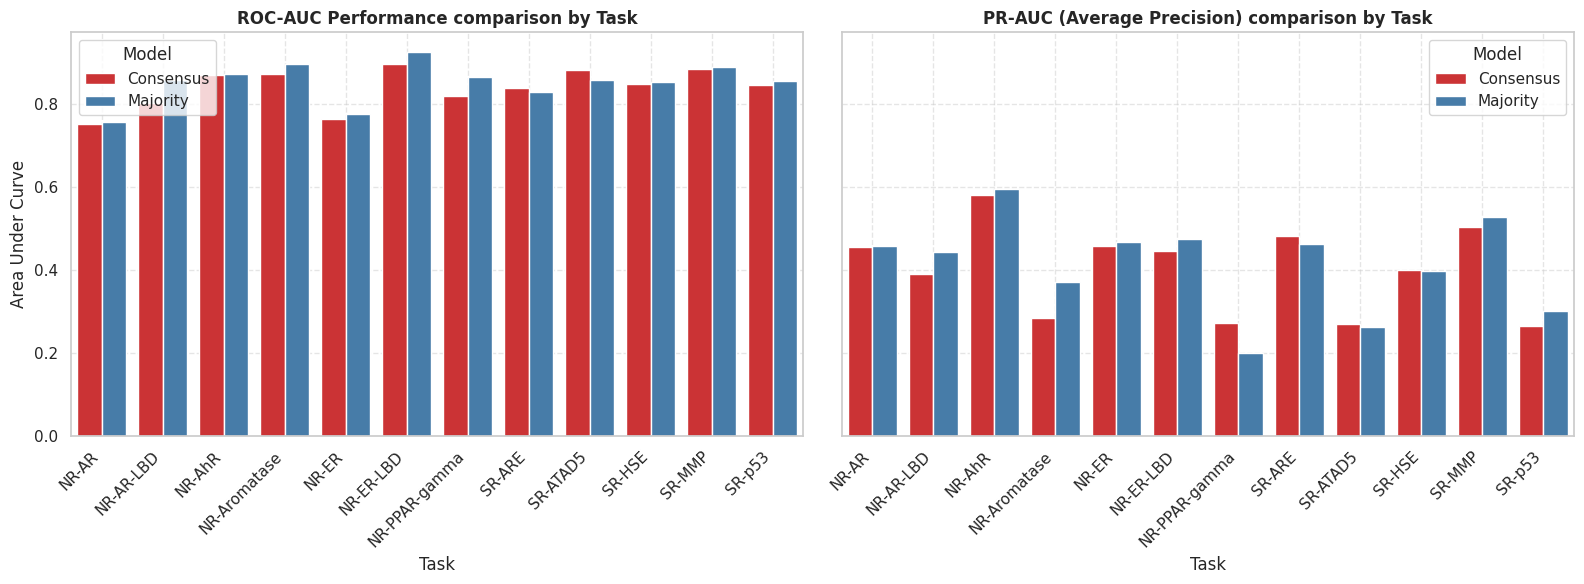

In [44]:

consensus_metrics = consensus_result["final_df"][["ROC_AUC", "PR_AUC"]].copy()
majority_metrics = majority_result["final_df"][["ROC_AUC", "PR_AUC"]].copy()

comparison_df = pd.merge(
    consensus_metrics,
    majority_metrics,
    left_index=True,
    right_index=True,
    suffixes=("_Consensus", "_Majority")
)

print("=== PER-TASK AUC METRICS COMPARISON ===")
display(comparison_df.round(4))

# Calculate overall macro-averages
macro_consensus_roc = comparison_df["ROC_AUC_Consensus"].mean()
macro_majority_roc = comparison_df["ROC_AUC_Majority"].mean()
macro_consensus_pr = comparison_df["PR_AUC_Consensus"].mean()
macro_majority_pr = comparison_df["PR_AUC_Majority"].mean()

print("\n=== OVERALL MACRO-AVERAGES ===")
print(f"Consensus Model   | Macro ROC-AUC: {macro_consensus_roc:.4f} | Macro PR-AUC: {macro_consensus_pr:.4f}")
print(f"Majority Model    | Macro ROC-AUC: {macro_majority_roc:.4f} | Macro PR-AUC: {macro_majority_pr:.4f}")

# Determine the superior model by criteria
if macro_consensus_roc > macro_majority_roc:
    better_roc = "Consensus Model"
else:
    better_roc = "Majority Model"

if macro_consensus_pr > macro_majority_pr:
    better_pr = "Consensus Model"
else:
    better_pr = "Majority Model"

print(f"\nVerdict:")
print(f" - By ROC-AUC: {better_roc} is better.")
print(f" - By PR-AUC:  {better_pr} is better.")

# 2. Professional visualization comparing both models
plot_data = []
for task in comparison_df.index:
    plot_data.append({"Task": task, "Model": "Consensus", "Metric": "ROC-AUC", "Score": comparison_df.loc[task, "ROC_AUC_Consensus"]})
    plot_data.append({"Task": task, "Model": "Majority", "Metric": "ROC-AUC", "Score": comparison_df.loc[task, "ROC_AUC_Majority"]})
    plot_data.append({"Task": task, "Model": "Consensus", "Metric": "PR-AUC", "Score": comparison_df.loc[task, "PR_AUC_Consensus"]})
    plot_data.append({"Task": task, "Model": "Majority", "Metric": "PR-AUC", "Score": comparison_df.loc[task, "PR_AUC_Majority"]})

vis_df = pd.DataFrame(plot_data)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
sns.barplot(data=vis_df[vis_df["Metric"] == "ROC-AUC"], x="Task", y="Score", hue="Model", ax=axes[0], palette="Set1")
axes[0].set_title("ROC-AUC Performance comparison by Task", fontweight="bold")
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha="right")
axes[0].set_ylabel("Area Under Curve")
axes[0].grid(True, linestyle="--", alpha=0.5)

sns.barplot(data=vis_df[vis_df["Metric"] == "PR-AUC"], x="Task", y="Score", hue="Model", ax=axes[1], palette="Set1")
axes[1].set_title("PR-AUC (Average Precision) comparison by Task", fontweight="bold")
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha="right")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [47]:

majority_metrics_df = pd.DataFrame(majority_result["final_df"])

# We isolate ROC_AUC and PR_AUC as they are threshold-independent measures of model discrimination
discrimination_df = majority_metrics_df[["N", "Positives", "Negatives", "ROC_AUC", "PR_AUC"]].copy()

print("=== MAJORITY VOTING MODEL: FINAL TEST DISCRIMINATION METRICS ===")
display(discrimination_df.round(4))

# Print the overall macro-averages
print(f"\nMacro-Average Test ROC-AUC: {discrimination_df['ROC_AUC'].mean():.4f}")
print(f"Macro-Average Test PR-AUC (Average Precision): {discrimination_df['PR_AUC'].mean():.4f}")

=== MAJORITY VOTING MODEL: FINAL TEST DISCRIMINATION METRICS ===


,N,Positives,Negatives,ROC_AUC,PR_AUC
NR-AR,743.0,17.0,726.0,0.7569,0.4570
NR-AR-LBD,688.0,15.0,673.0,0.8589,0.4431
NR-AhR,677.0,60.0,617.0,0.8715,0.5952
NR-Aromatase,603.0,28.0,575.0,0.8954,0.3705
NR-ER,628.0,55.0,573.0,0.7762,0.4674
NR-ER-LBD,706.0,16.0,690.0,0.9264,0.4733
NR-PPAR-gamma,663.0,17.0,646.0,0.8655,0.1994
SR-ARE,564.0,78.0,486.0,0.8300,0.4616
SR-ATAD5,724.0,20.0,704.0,0.8580,0.2623
SR-HSE,639.0,41.0,598.0,0.8533,0.3983



Macro-Average Test ROC-AUC: 0.8531
Macro-Average Test PR-AUC (Average Precision): 0.4130


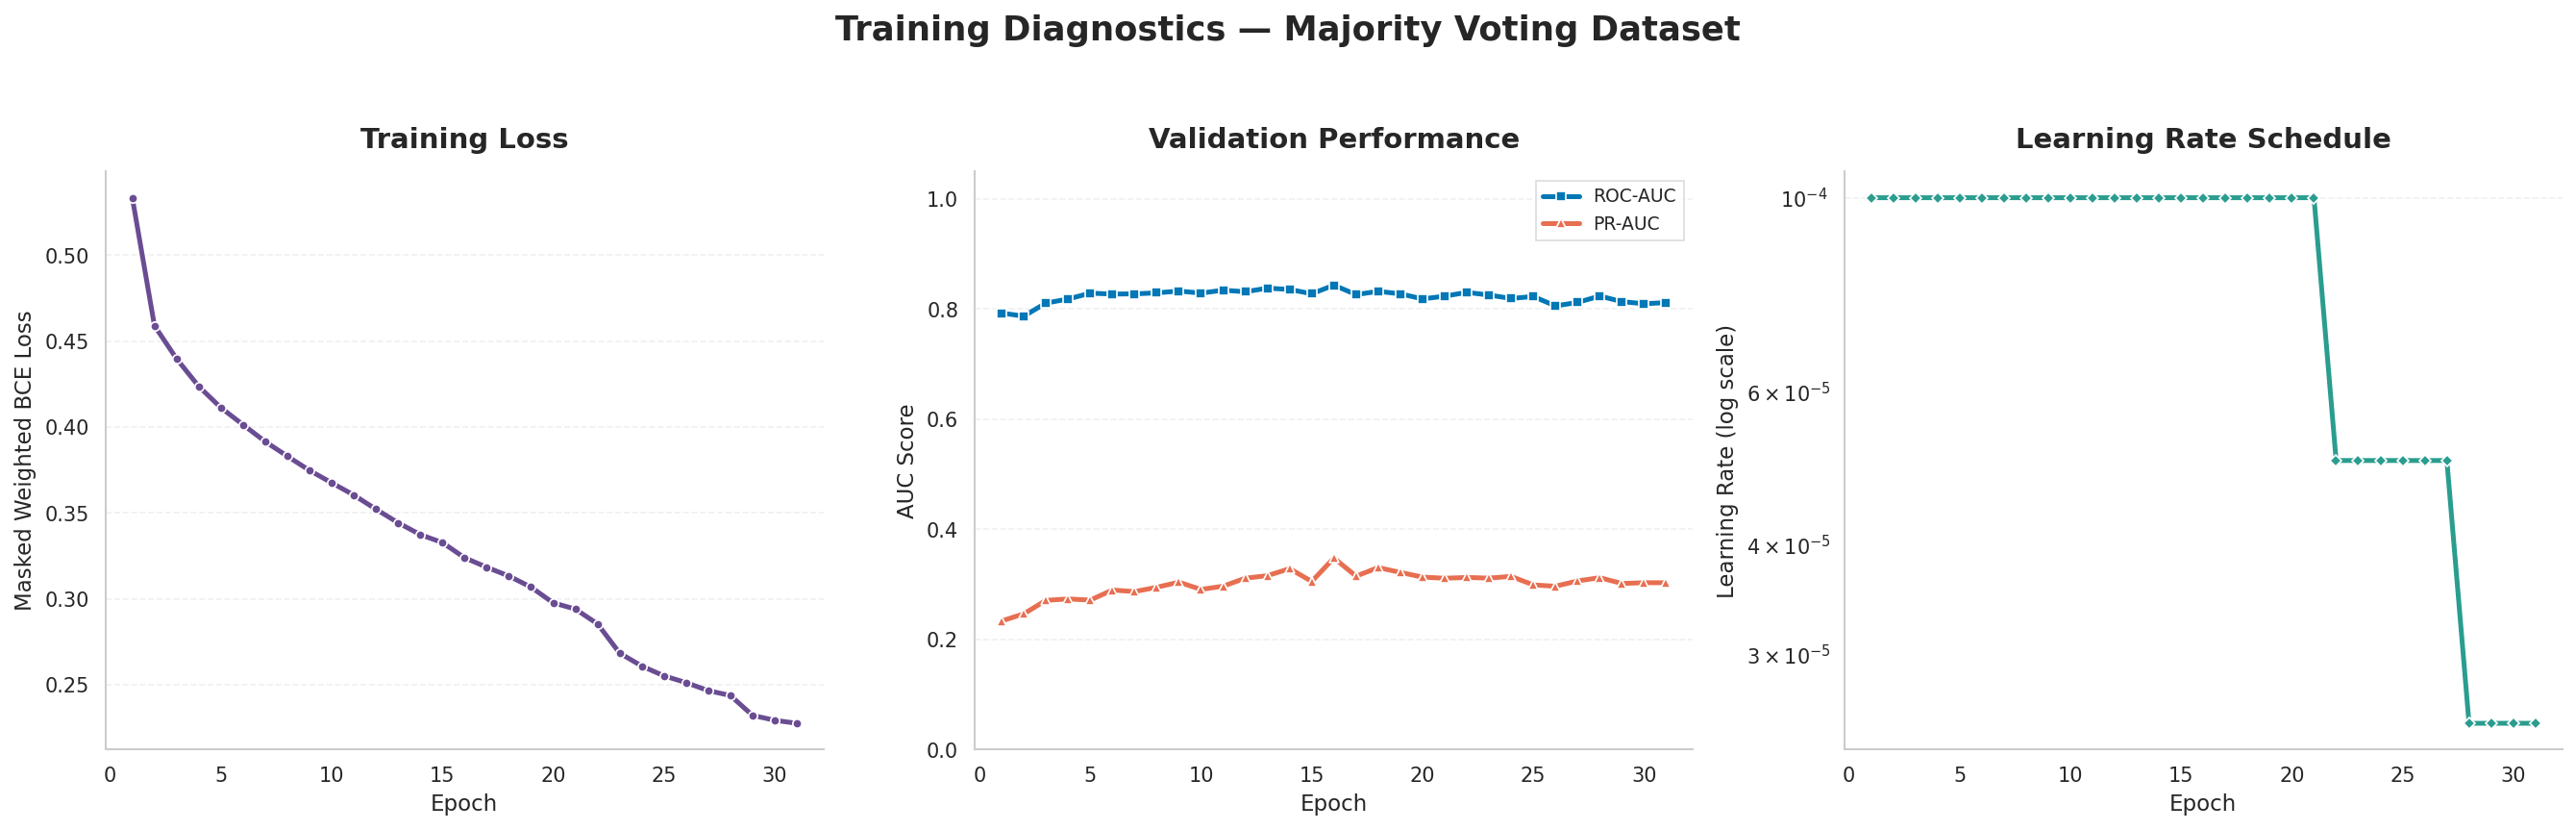

In [51]:

sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 9,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
})

COLORS = {
    "train_loss": "#6A4C93",  # Purple
    "val_roc": "#0077B6",     # Deep blue
    "val_pr": "#E76F51",      # Coral
    "lr": "#2A9D8F",           # Teal
}

history_df = majority_result["history"].copy()

if history_df.empty:
    print("Training history is empty. Nothing to plot.")

else:
    required_columns = ["epoch", "train_loss", "val_auc", "lr"]
    missing_columns = [
        col for col in required_columns
        if col not in history_df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Missing required history columns: {missing_columns}"
        )

    history_df = (
        history_df
        .sort_values("epoch")
        .reset_index(drop=True)
    )

    fig, axes = plt.subplots(
        nrows=1,
        ncols=3,
        figsize=(18, 5.5)
    )

    fig.suptitle(
        "Training Diagnostics — Majority Voting Dataset",
        fontsize=17,
        fontweight="bold",
        y=1.04
    )

    ax = axes[0]

    ax.plot(
        history_df["epoch"],
        history_df["train_loss"],
        color=COLORS["train_loss"],
        linewidth=2.4,
        marker="o",
        markersize=4.5,
        markeredgecolor="white",
        markeredgewidth=0.8
    )

    ax.set_title("Training Loss", pad=12)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Masked Weighted BCE Loss")

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.3
    )
    ax.grid(axis="x", visible=False)


    ax = axes[1]

    ax.plot(
        history_df["epoch"],
        history_df["val_auc"],
        color=COLORS["val_roc"],
        linewidth=2.4,
        marker="s",
        markersize=4.5,
        markeredgecolor="white",
        markeredgewidth=0.8,
        label="ROC-AUC"
    )

    if "val_pr_auc" in history_df.columns:
        ax.plot(
            history_df["epoch"],
            history_df["val_pr_auc"],
            color=COLORS["val_pr"],
            linewidth=2.4,
            marker="^",
            markersize=4.5,
            markeredgecolor="white",
            markeredgewidth=0.8,
            label="PR-AUC"
        )

    ax.set_title("Validation Performance", pad=12)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("AUC Score")
    ax.set_ylim(0, 1.05)

    ax.legend(
        loc="best",
        frameon=True,
        fancybox=False,
        edgecolor="lightgray"
    )

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.3
    )
    ax.grid(axis="x", visible=False)

    ax = axes[2]

    lr_values = pd.to_numeric(
        history_df["lr"],
        errors="coerce"
    )

    valid_lr = (
        np.isfinite(lr_values) &
        (lr_values > 0)
    )

    if valid_lr.any():
        ax.plot(
            history_df.loc[valid_lr, "epoch"],
            lr_values.loc[valid_lr],
            color=COLORS["lr"],
            linewidth=2.4,
            marker="D",
            markersize=4,
            markeredgecolor="white",
            markeredgewidth=0.8
        )

        ax.set_yscale("log")
        ax.set_ylabel("Learning Rate (log scale)")

    else:
        ax.text(
            0.5,
            0.5,
            "No positive learning-rate values",
            ha="center",
            va="center",
            transform=ax.transAxes
        )
        ax.set_ylabel("Learning Rate")

    ax.set_title("Learning Rate Schedule", pad=12)
    ax.set_xlabel("Epoch")

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.3
    )
    ax.grid(axis="x", visible=False)

    for ax in axes:
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.margins(x=0.04)

    plt.tight_layout()
    plt.show()



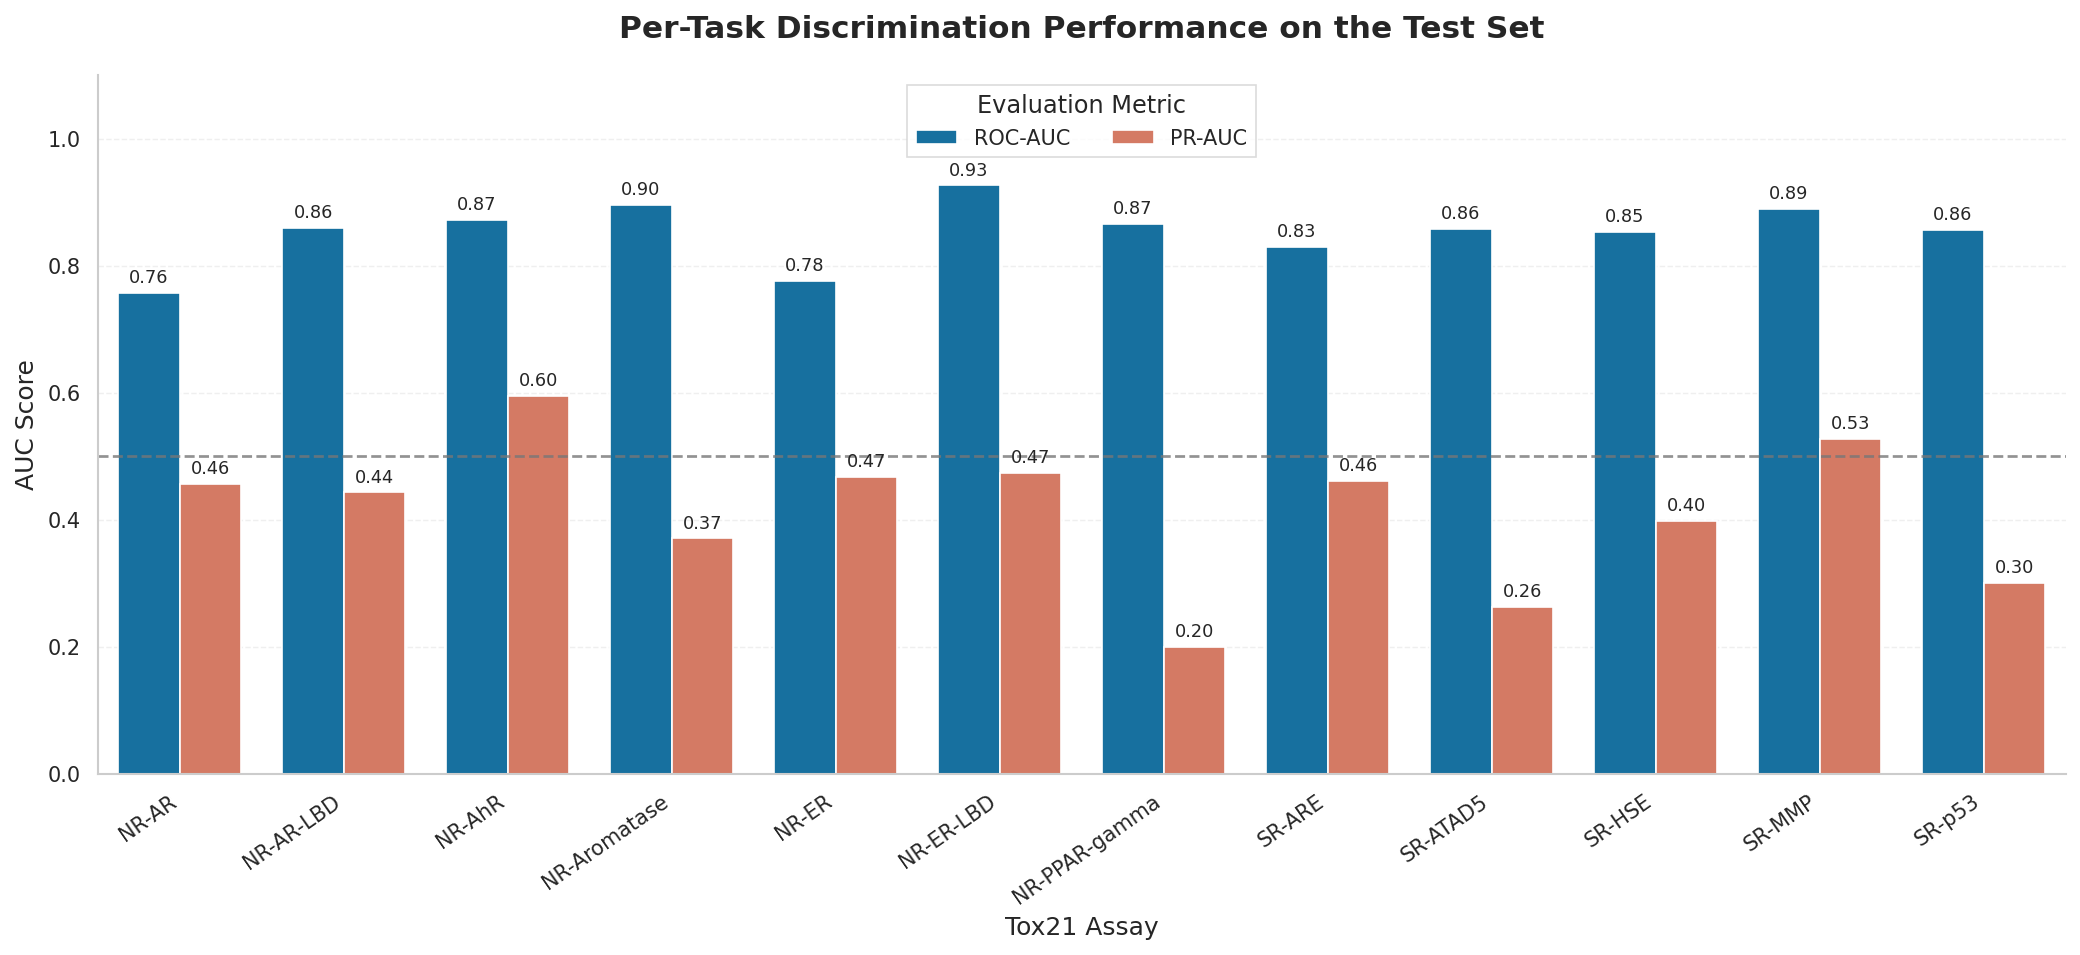


       FINAL TEST SET — MACRO PERFORMANCE
Macro ROC-AUC : 0.8531
Macro PR-AUC  : 0.4130


In [52]:

sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold"
})

COLORS = {
    "ROC-AUC": "#0077B6",
    "PR-AUC": "#E76F51"
}

final_auc_df = (
    majority_result["final_df"]
    .reset_index()
    .rename(columns={"index": "Task"})
)

required_metrics = ["ROC_AUC", "PR_AUC"]

missing_metrics = [
    col for col in required_metrics
    if col not in final_auc_df.columns
]

if missing_metrics:
    raise ValueError(
        f"Missing required metrics: {missing_metrics}"
    )

final_auc_df["Task"] = final_auc_df["Task"].astype(str)

task_order = final_auc_df["Task"].tolist()

plot_df = final_auc_df.melt(
    id_vars="Task",
    value_vars=required_metrics,
    var_name="Metric",
    value_name="Score"
)

plot_df["Score"] = pd.to_numeric(
    plot_df["Score"],
    errors="coerce"
)

plot_df = plot_df[
    np.isfinite(plot_df["Score"])
].copy()

plot_df["Metric"] = plot_df["Metric"].map({
    "ROC_AUC": "ROC-AUC",
    "PR_AUC": "PR-AUC"
})

# ============================================================
# 3. PLOT PER-TASK TEST PERFORMANCE
# ============================================================

fig, ax = plt.subplots(figsize=(14, 6.5))

sns.barplot(
    data=plot_df,
    x="Task",
    y="Score",
    hue="Metric",
    order=task_order,
    hue_order=["ROC-AUC", "PR-AUC"],
    palette=COLORS,
    edgecolor="white",
    linewidth=0.8,
    width=0.75,
    ax=ax
)

ax.axhline(
    y=0.5,
    color="#777777",
    linestyle="--",
    linewidth=1.3,
    alpha=0.8,
    label="_nolegend_"
)

for container in ax.containers:
    labels = [
        f"{bar.get_height():.2f}"
        if np.isfinite(bar.get_height())
        else ""
        for bar in container
    ]

    ax.bar_label(
        container,
        labels=labels,
        padding=3,
        fontsize=8.5
    )

ax.set_title(
    "Per-Task Discrimination Performance on the Test Set",
    pad=18
)

ax.set_xlabel("Tox21 Assay")
ax.set_ylabel("AUC Score")
ax.set_ylim(0, 1.10)

ax.set_xticks(np.arange(len(task_order)))
ax.set_xticklabels(
    task_order,
    rotation=35,
    ha="right"
)

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.7,
    alpha=0.3
)
ax.grid(axis="x", visible=False)

ax.legend(
    title="Evaluation Metric",
    loc="upper center",
    bbox_to_anchor=(0.5, 1.0),
    ncol=2,
    frameon=True,
    fancybox=False,
    edgecolor="lightgray"
)

sns.despine(ax=ax)

plt.tight_layout()
plt.show()

macro_roc = majority_result["final_metrics"]["ROC_AUC"]
macro_pr = majority_result["final_metrics"]["PR_AUC"]

print("\n" + "=" * 52)
print("       FINAL TEST SET — MACRO PERFORMANCE")
print("=" * 52)
print(f"Macro ROC-AUC : {macro_roc:.4f}")
print(f"Macro PR-AUC  : {macro_pr:.4f}")
print("=" * 52)
